# Polígonos Regulares e Comprimento da Circunferência

**Módulo:** 04 – Geometria Plana

**Pré-requisitos:** [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (casos LAL e LLL, propriedades do triângulo isósceles), [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (mediatrizes, bissetrizes, circuncentro e incentro), [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (soma dos ângulos internos e externos, definição de polígono regular), [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (circunferências inscrita e circunscrita, corda e flecha), [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulo central e medida angular de um arco), [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (razão de semelhança), [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (o **Teorema de Pitágoras** e os triângulos notáveis 45°–45°–90° e 30°–60°–90°) e [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) ($S = p \cdot r$ e área por decomposição em triângulos).

**Objetivos de aprendizagem:** ao final você será capaz de...
- Identificar os elementos de um polígono regular (centro, raio, apótema, ângulos central, interno e externo) e explicar por que todo polígono regular é **inscritível e circunscritível**, com as duas circunferências de mesmo centro.
- Calcular lado, apótema, perímetro e área dos regulares mais importantes (triângulo equilátero, quadrado, hexágono, octógono e dodecágono), relacionando **lado, apótema e raio** por Pitágoras.
- Explicar por que a razão $C/d$ é a **mesma** em toda circunferência (o número $\pi$) e usar $C = 2\pi r$, inclusive para o **comprimento de um arco**.
- Calcular $\pi$ com **polígonos inscritos e circunscritos**, ao modo de Arquimedes, e perceber os limites da aritmética do computador.

**Tempo estimado:** 90 a 105 minutos (é um notebook denso: vale dividir em duas sessões, uma para as seções 1 a 3 e outra para as seções 4 e 5)

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leandrofreiredealmeida/curso_matematica_python/blob/main/04_geometria_plana/0418a_poligonos_regulares_e_comprimento_da_circunferencia.ipynb)

## Medir o curvo com uma régua reta

Um fio dá **exatamente uma volta** em torno de um prato de 10 cm de raio. Quanto mede o fio? Fácil: estique o fio e meça. Mas, e se você **não** tiver o fio, só uma **régua**, que é reta? Como medir uma linha curva com um instrumento que só mede segmentos?

Uma ideia antiga: trocar a curva por **pedaços retos**. Marque alguns pontos igualmente espaçados na circunferência e ligue-os: o resultado é um **polígono regular inscrito**, e os lados dele (cordas, de [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)) a régua mede sem problema. Com poucos pontos, o polígono fica "quadradão" e longe da curva; com muitos pontos, ele quase se **cola** nela. O widget abaixo faz o experimento numa circunferência de **raio 1** (logo depois da célula de preparação).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Arc, Circle, Polygon, Wedge

# Paleta de cores Nord
NORD_FUNDO = "#2E3440"
NORD_PAINEL = "#3B4252"
NORD_LINHA = "#4C566A"
NORD_TEXTO = "#ECEFF4"
NORD_TEXTO_SEC = "#D8DEE9"
COR_PONTO = "#88C0D0"
COR_DESTAQUE = "#A3BE8C"
COR_ALERTA = "#BF616A"
COR_SECUNDARIA = "#81A1C1"
COR_EXTRA = "#B48EAD"
COR_AVISO = "#EBCB8B"


def estilizar_eixo(ax) -> None:
    """Aplica o estilo Nord padrão a um eixo do matplotlib."""
    ax.set_facecolor(NORD_FUNDO)
    ax.tick_params(colors=NORD_TEXTO_SEC)
    for spine in ax.spines.values():
        spine.set_color(NORD_LINHA)
    ax.grid(color=NORD_LINHA, linewidth=0.5, alpha=0.5)


# Ferramentas de desenho e de medida dos notebooks anteriores (0401a, 0402a, 0407a, 0410a, 0411a, 0412a e 0415a)

def preparar_eixo(ax, pontos, margem: float = 0.8) -> None:
    """Deixa o eixo pronto para desenhos de geometria (estilo Nord, sem grade, sem números,
    escala igual) e enquadra todos os `pontos` com uma margem em volta."""
    estilizar_eixo(ax)
    ax.grid(False)
    xs = [p[0] for p in pontos]
    ys = [p[1] for p in pontos]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])


def direcao(angulo_graus: float) -> np.ndarray:
    """Vetor de tamanho 1 apontando na direção dada, em graus, a partir da horizontal (sentido anti-horário).

    (cos e sin vêm da Trigonometria, módulo 05; aqui só servem para apontar na direção certa.)
    """
    rad = math.radians(angulo_graus)
    return np.array([math.cos(rad), math.sin(rad)])


def direcao_de(origem, destino) -> float:
    """Direção, em graus, em que `destino` está quando visto de `origem`."""
    return math.degrees(math.atan2(destino[1] - origem[1], destino[0] - origem[0]))


def medir_angulo(vertice, P, Q) -> float:
    """Transferidor digital: medida, em graus, do ângulo com vértice em `vertice`
    formado pelas semirretas que passam por P e por Q (resultado entre 0° e 180°)."""
    u = np.subtract(P, vertice)
    v = np.subtract(Q, vertice)
    cosseno = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
    return math.degrees(math.acos(np.clip(cosseno, -1, 1)))


def cruzamento(P, inclinacao_1: float, Q, inclinacao_2: float):
    """Ponto em que a reta que passa por P (com a inclinação `inclinacao_1`, em graus) cruza a reta
    que passa por Q (com a inclinação `inclinacao_2`). Devolve None se as duas retas tiverem a mesma
    direção, porque aí elas não se cruzam num ponto só.

    Por trás, é um sistema linear 2×2 (módulo 03): P + t·u = Q + k·v, com incógnitas t e k.
    """
    matriz = np.column_stack([direcao(inclinacao_1), -direcao(inclinacao_2)])
    if abs(np.linalg.det(matriz)) < 1e-12:
        return None
    t, _ = np.linalg.solve(matriz, np.subtract(Q, P))
    return np.array(P, dtype=float) + t * direcao(inclinacao_1)


def ponto_medio(P, Q) -> np.ndarray:
    """Ponto médio do segmento PQ: a média das coordenadas (0402a)."""
    return (np.asarray(P, dtype=float) + np.asarray(Q, dtype=float)) / 2


def iguais(x: float, y: float) -> bool:
    """Compara duas medidas com uma tolerância pequena (as contas com float têm arredondamentos)."""
    return math.isclose(x, y, rel_tol=1e-9, abs_tol=1e-6)


def desenhar_ponto(ax, p, nome: str = "", cor: str = COR_AVISO, deslocamento=(0.12, 0.15),
                   tamanho_fonte: int = 13) -> None:
    """Desenha um ponto com seu nome (letra maiúscula) ao lado."""
    ax.plot(*p, "o", color=cor, markersize=7, zorder=6)
    if nome:
        ax.text(p[0] + deslocamento[0], p[1] + deslocamento[1], nome, color=NORD_TEXTO, fontsize=tamanho_fonte,
                fontweight="bold", zorder=7)


def desenhar_segmento(ax, P, Q, cor: str = NORD_TEXTO, largura: float = 3.0, estilo: str = "-",
                      alpha: float = 1.0, zorder: int = 5) -> None:
    """Desenha o segmento PQ (só o pedaço entre P e Q)."""
    ax.plot(*zip(P, Q), color=cor, lw=largura, linestyle=estilo, alpha=alpha, zorder=zorder,
            solid_capstyle="round")


def desenhar_setor(ax, vertice, inicio: float, abertura: float, raio: float = 0.5, cor: str = COR_PONTO,
                   rotulo: str | None = None, marcar_reto: bool = True, raio_rotulo: float | None = None,
                   tamanho_fonte: int = 11) -> None:
    """Pinta o ângulo com vértice em `vertice` que começa na direção `inicio` e gira `abertura`
    graus no sentido anti-horário. O ângulo reto ganha o quadradinho no lugar do arco."""
    v = np.array(vertice, dtype=float)
    if marcar_reto and math.isclose(abertura, 90, abs_tol=1e-6):
        lado = 0.6 * raio
        canto = [v, v + lado * direcao(inicio), v + lado * (direcao(inicio) + direcao(inicio + 90)),
                 v + lado * direcao(inicio + 90)]
        ax.add_patch(Polygon(canto, closed=True, facecolor=cor, alpha=0.35, edgecolor=cor, lw=2))
    else:
        ax.add_patch(Wedge(v, raio, inicio, inicio + abertura, facecolor=cor, alpha=0.3, edgecolor="none"))
        ax.add_patch(Arc(v, 2 * raio, 2 * raio, theta1=inicio, theta2=inicio + abertura, color=cor, lw=2))
    if rotulo:
        distancia_rotulo = 1.6 * raio if raio_rotulo is None else raio_rotulo
        posicao = v + distancia_rotulo * direcao(inicio + abertura / 2)
        ax.text(*posicao, rotulo, color=cor, fontsize=tamanho_fonte, ha="center", va="center", fontweight="bold")


def desenhar_arco(ax, vertice, p, q, **opcoes) -> None:
    """Marca o ângulo de vértice `vertice` formado pelas semirretas que passam por p e por q
    (sempre a abertura menor, entre 0° e 180°). Aceita as mesmas opções de `desenhar_setor`."""
    inicio = direcao_de(vertice, p) % 360
    abertura = (direcao_de(vertice, q) - inicio) % 360
    if abertura > 180:
        inicio, abertura = direcao_de(vertice, q) % 360, 360 - abertura
    desenhar_setor(ax, vertice, inicio, abertura, **opcoes)


def rotular_fora(ax, P, texto: str, centro, cor: str = NORD_TEXTO, distancia: float = 0.35,
                 tamanho: int = 12) -> None:
    """Escreve `texto` perto do ponto P, afastado do `centro` (para não ficar em cima da figura)."""
    P = np.asarray(P, dtype=float)
    afastar = P - np.asarray(centro, dtype=float)
    afastar = afastar / np.linalg.norm(afastar) if np.linalg.norm(afastar) > 0 else np.array([0.0, 1.0])
    ax.text(*(P + distancia * afastar), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def rotular_segmento(ax, P, Q, texto: str, cor: str = NORD_TEXTO, distancia: float = 0.35, longe_de=None,
                     tamanho: int = 11) -> None:
    """Escreve `texto` ao lado do meio do segmento PQ, afastado `distancia` na direção perpendicular a ele.
    Se `longe_de` for um ponto, o texto vai para o lado do segmento oposto a esse ponto."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    u = (Q - P) / np.linalg.norm(Q - P)
    normal = np.array([-u[1], u[0]])
    meio = (P + Q) / 2
    if longe_de is not None and np.dot(meio - np.asarray(longe_de, dtype=float), normal) < 0:
        normal = -normal
    ax.text(*(meio + distancia * normal), texto, color=cor, fontsize=tamanho, fontweight="bold",
            ha="center", va="center", zorder=7)


def escrever_checklist(ax, itens, titulo: str = "") -> None:
    """Painel de texto com uma linha por item (texto, ok): ✓ verde quando vale, ✗ vermelho quando não (0410a)."""
    ax.set_facecolor(NORD_FUNDO)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    if titulo:
        ax.text(0.0, 0.97, titulo, color=NORD_TEXTO, fontsize=12, fontweight="bold", va="top")
    passo = min(0.13, 0.85 / max(len(itens), 1))
    for k, (texto, ok) in enumerate(itens):
        ax.text(0.0, 0.84 - k * passo, f"{'✓' if ok else '✗'}  {texto}", color=COR_DESTAQUE if ok else COR_ALERTA,
                fontsize=11, va="top")


def desenhar_circunferencia(ax, O, r: float, cor: str = COR_PONTO, estilo: str = "-",
                            largura: float = 2.5, preencher: bool = False, opacidade: float = 0.15) -> None:
    """Desenha a circunferência de centro O e raio r (a linha). Com `preencher=True`, pinta também a
    região interna: o círculo (0412a)."""
    O = tuple(np.asarray(O, dtype=float))
    if preencher:
        ax.add_patch(Circle(O, r, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Circle(O, r, fill=False, edgecolor=cor, lw=largura, linestyle=estilo, zorder=3))


def cruzamento_circunferencias(P, r1: float, Q, r2: float):
    """Um ponto comum às circunferências λ(P, r1) e λ(Q, r2): o que fica à ESQUERDA de quem anda de P para Q
    (0415a). Devolve None se as duas circunferências não se cruzam."""
    P, Q = np.asarray(P, dtype=float), np.asarray(Q, dtype=float)
    d = math.dist(P, Q)
    if not abs(r1 - r2) < d < r1 + r2:
        return None
    x = (d**2 + r1**2 - r2**2) / (2 * d)
    y = math.sqrt(r1**2 - x**2)
    u = (Q - P) / d
    return P + x * u + y * np.array([-u[1], u[0]])



# Ferramentas novas deste notebook
# Notação fixa: n = número de lados; ℓ = lado (verde); R = raio da circunscrita (azul); a = apótema = raio da
# inscrita (laranja); α = ângulo central (amarelo). O polígono inscrito é azul-claro e o circunscrito é roxo.
COR_POLIGONO = COR_PONTO  # polígono regular (inscrito): azul-claro
COR_LADO = COR_DESTAQUE  # lado ℓ: verde
COR_RAIO = COR_SECUNDARIA  # raio R e circunferência circunscrita: azul (tom frio)
COR_CIRCUNSCRITA = COR_SECUNDARIA
COR_APOTEMA = "#D08770"  # apótema a e circunferência inscrita: laranja (tom quente)
COR_INSCRITA = "#D08770"
COR_CENTRAL = COR_AVISO  # ângulo central α e arcos medidos: amarelo
COR_INTERNO = "#8FBCBB"  # ângulo interno: verde-água
COR_EXTERNO = COR_EXTRA  # ângulo externo: roxo
COR_CIRCUNSCRITO = COR_EXTRA  # polígono circunscrito: roxo


def vertices_regular(n: int, R: float = 1.0, centro=(0.0, 0.0), rotacao: float | None = None) -> np.ndarray:
    """Vértices do polígono regular de n lados inscrito na circunferência λ(centro, R): n pontos dela separados
    por 360°/n, o primeiro na direção `rotacao` (em graus). Sem `rotacao`, o polígono fica "apoiado" num lado
    horizontal: o lado entre os vértices 0 e 1 é o de baixo (0411a).

    (A direção de cada vértice usa `direcao`, que vem da Trigonometria; aqui ela só aponta os vértices.)
    """
    inicio = -90 - 180 / n if rotacao is None else rotacao
    c = np.asarray(centro, dtype=float)
    return np.array([c + R * direcao(inicio + 360 * k / n) for k in range(n)])


def desenhar_poligono(ax, vertices, cor: str = COR_POLIGONO, largura: float = 2.5, preencher: bool = True,
                      opacidade: float = 0.15, estilo: str = "-", zorder: int = 4) -> None:
    """Desenha o polígono de vértices dados (fechado), com preenchimento claro opcional."""
    if preencher:
        ax.add_patch(Polygon(vertices, closed=True, facecolor=cor, alpha=opacidade, edgecolor="none", zorder=1))
    ax.add_patch(Polygon(vertices, closed=True, fill=False, edgecolor=cor, lw=largura, linestyle=estilo,
                         zorder=zorder))

🕹️ **Widget interativo — trocando o curvo pelo reto:** o slider escolhe o número $n$ de pontos (de 3 a 96). À esquerda, o polígono regular inscrito na circunferência de raio 1; à direita, o **perímetro** do polígono (a soma dos $n$ lados, medidos como distâncias entre vértices consecutivos) para todos os valores de $n$, com o seu $n$ destacado. Passe por $n = 6, 12, 24, 48$ e $96$ e anote os perímetros.

In [ ]:
def explorar_medir_curva(n: int) -> None:
    vertices = vertices_regular(n, 1.0)
    perimetro = sum(math.dist(vertices[k], vertices[(k + 1) % n]) for k in range(n))
    todos_n = np.arange(3, 97)
    todos_p = [sum(math.dist(V[k], V[(k + 1) % m]) for k in range(m)) for m, V in
               ((m, vertices_regular(m, 1.0)) for m in todos_n)]

    fig, (ax, ax_g) = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})
    fig.patch.set_facecolor(NORD_FUNDO)
    preparar_eixo(ax, [(-1, -1), (1, 1)], margem=0.2)
    desenhar_circunferencia(ax, (0, 0), 1.0, cor=COR_CENTRAL, largura=2, estilo="--")
    desenhar_poligono(ax, vertices)
    for P in vertices:
        ax.plot(*P, "o", color=NORD_TEXTO, markersize=max(2, 7 - n / 15), zorder=6)
    ax.set_title(f"n = {n} lados   →   perímetro = {perimetro:.4f}", color=NORD_TEXTO, fontsize=13)

    estilizar_eixo(ax_g)
    ax_g.plot(todos_n, todos_p, color=COR_POLIGONO, lw=2)
    ax_g.plot(n, perimetro, "o", color=COR_AVISO, markersize=10, zorder=5)
    ax_g.axhline(todos_p[-1], color=NORD_TEXTO_SEC, lw=1, linestyle=":")
    ax_g.text(60, todos_p[-1] - 0.06, "para onde vai?", color=NORD_TEXTO_SEC, fontsize=11, va="top")
    ax_g.set_xlabel("número de lados n", color=NORD_TEXTO)
    ax_g.set_ylabel("perímetro do polígono inscrito", color=NORD_TEXTO)
    ax_g.set_ylim(5, 6.5)
    ax_g.set_title("O perímetro cresce, mas cada vez mais devagar", color=NORD_TEXTO, fontsize=13)
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_medir_curva, n=widgets.IntSlider(value=6, min=3, max=96, step=1, description="n:"));

interactive(children=(IntSlider(value=6, description='n:', max=96, min=3), Output()), _dom_classes=('widget-in…

Os números que você deve ter anotado:

| $n$ | 6 | 12 | 24 | 48 | 96 |
|---|---|---|---|---|---|
| perímetro do inscrito (raio 1) | 6,0000 | 6,2117 | 6,2653 | 6,2787 | 6,2821 |

O perímetro **cresce** a cada dobra, mas o crescimento vai ficando minúsculo: parece que existe um número, perto de **6,28**, do qual o perímetro se aproxima sem nunca passar. Esse número tem nome? Tem, e é famoso. Na seção 4 ele ganha nome, e na seção 5 você vai calculá-lo com 15 casas decimais, usando **só o Teorema de Pitágoras**. A ideia de medir o curvo pelo reto é de **Arquimedes**, e ela é o fio condutor deste notebook.

## Por que as abelhas fazem hexágonos?

Os favos de mel são formados por células **hexagonais**, todas iguais, encaixadas sem deixar nenhum buraco. Por que hexágonos? Por que não pentágonos, ou octógonos? Tente você: pegue várias cópias de um mesmo polígono regular e encaixe-as em volta de um ponto, lado com lado. Com hexágonos dá certo (à esquerda); com pentágonos, três cópias deixam um **buraco** e uma quarta cópia não cabe (à direita).

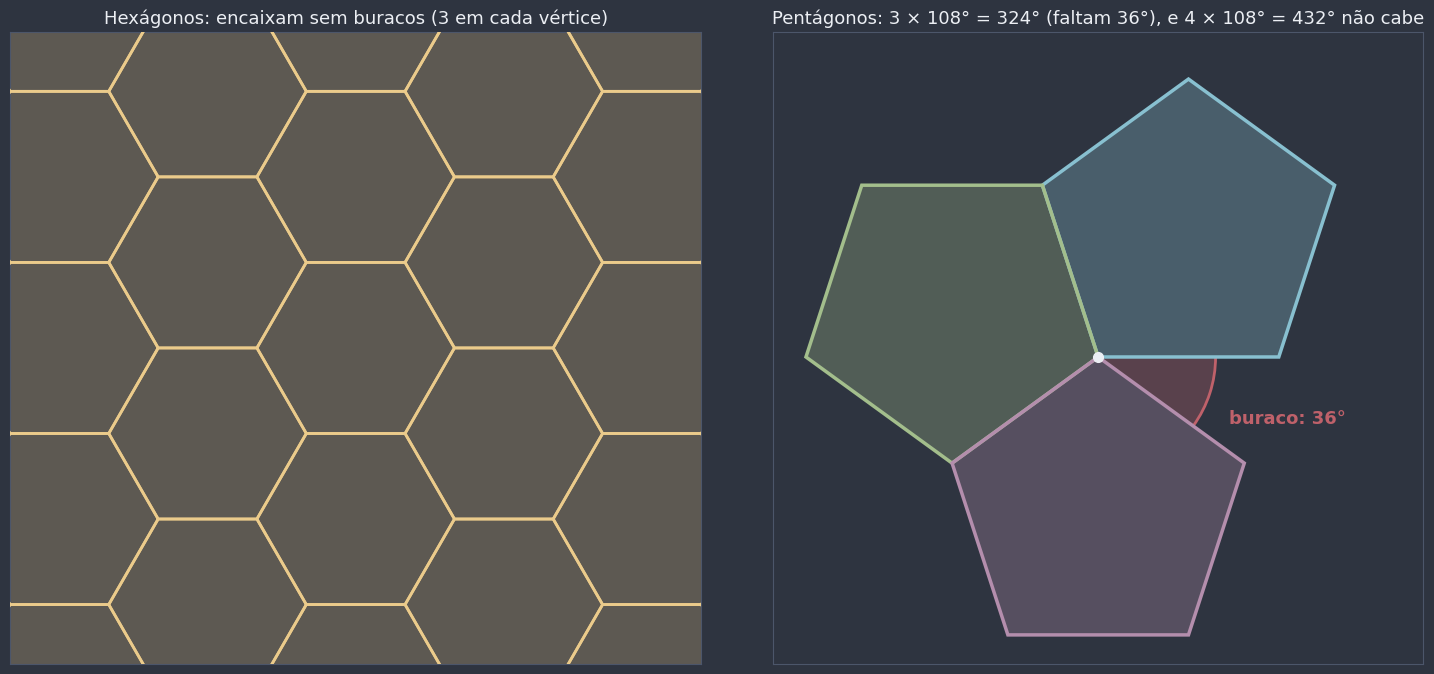

In [3]:
def poligono_por_lado(P, direcao_inicial: float, n: int, lado: float) -> np.ndarray:
    """Polígono regular de n lados com um vértice em P e o primeiro lado saindo de P na direção dada:
    anda-se pelo contorno virando o ângulo externo 360°/n a cada vértice (0411a). O interior fica à esquerda."""
    vertices, atual = [np.asarray(P, dtype=float)], np.asarray(P, dtype=float)
    for k in range(n - 1):
        atual = atual + lado * direcao(direcao_inicial + k * 360 / n)
        vertices.append(atual)
    return np.array(vertices)


fig, (ax_f, ax_p) = plt.subplots(1, 2, figsize=(15, 6.8))
fig.patch.set_facecolor(NORD_FUNDO)

# O favo: hexágonos com um lado "deitado", em colunas deslocadas
R_f = 1.0
for i in range(-3, 4):
    for j in range(-3, 4):
        centro = (1.5 * R_f * i, math.sqrt(3) * R_f * (j + (i % 2) / 2))
        desenhar_poligono(ax_f, vertices_regular(6, R_f, centro, rotacao=0), cor=COR_AVISO, opacidade=0.25,
                          largura=2)
preparar_eixo(ax_f, [(-3.5, -3.2), (3.5, 3.2)], margem=0)
ax_f.set_title("Hexágonos: encaixam sem buracos (3 em cada vértice)", color=NORD_TEXTO, fontsize=13)

# Três pentágonos em volta de um ponto: sobra um buraco
P0 = np.array([0.0, 0.0])
cores = (COR_POLIGONO, COR_DESTAQUE, COR_EXTRA)
for k, cor in enumerate(cores):
    desenhar_poligono(ax_p, poligono_por_lado(P0, 108 * k, 5, 2.0), cor=cor, opacidade=0.3)
desenhar_setor(ax_p, P0, 324, 36, raio=1.3, cor=COR_ALERTA, rotulo="buraco: 36°", raio_rotulo=2.2,
               tamanho_fonte=13)
desenhar_ponto(ax_p, P0, cor=NORD_TEXTO)
preparar_eixo(ax_p, [(-3.6, -3.4), (3.6, 3.6)], margem=0)
ax_p.set_title("Pentágonos: 3 × 108° = 324° (faltam 36°), e 4 × 108° = 432° não cabe", color=NORD_TEXTO,
               fontsize=13)
plt.tight_layout()
plt.show()

Os ângulos internos do pentágono regular medem 108° ([`0411a_poligonos.ipynb`](0411a_poligonos.ipynb)): três deles somam 324°, e os 36° que faltam viram buraco. A pergunta fica aberta por enquanto: **quais** polígonos regulares conseguem cobrir o plano sozinhos? A resposta (são só três!) aparece na seção 2.

### O fio condutor deste notebook

Os notebooks anteriores do módulo deixaram várias **promessas** para cá. Todas são entregues aqui:

| Prometido em | Promessa | Onde |
|---|---|---|
| 0410a | as circunferências inscrita e circunscrita de um polígono regular, com o **mesmo centro** | seção 1 |
| 0411a | os ângulos interno $\frac{(n - 2) \cdot 180°}{n}$ e externo $\frac{360°}{n}$, centro, raio e **apótema** | seções 1 e 2 |
| 0411a | o polígono com $n$ crescente "virando" a circunferência, agora **formalizado** | seções 4 e 5 |
| 0412a | polígonos inscritos e circunscritos; o **comprimento da circunferência** | seções 3 e 4 |
| 0413a | o ângulo central $\frac{360°}{n}$ e o **comprimento de um arco** (que não é a medida angular) | seções 1 e 4 |
| 0415a | dois polígonos regulares com o mesmo $n$ são **semelhantes** | seções 1 e 3 |
| 0416a | apótema, raio e lado dos regulares por **Pitágoras e triângulos notáveis** | seção 2 |
| 0417a | área por **decomposição em triângulos**: de $S = p \cdot r$ para $S = p \cdot a$ | seção 3 |

E a história tem uma direção só:

$$\text{polígono regular} \;\longrightarrow\; \text{mais lados} \;\longrightarrow\; \text{quase uma circunferência} \;\longrightarrow\; \text{perímetro} \;\longrightarrow\; \text{comprimento } C \;\longrightarrow\; \pi$$

| Seção | A ideia em uma frase | Ferramenta |
|---|---|---|
| 1. O polígono regular e suas duas circunferências | todo regular é inscritível e circunscritível; $R^2 = a^2 + (\ell/2)^2$ | congruência (0405a), mediatrizes (0410a), Pitágoras (0416a) |
| 2. Os regulares "de bolso" | $\ell$ e $a$ de $n = 3, 4, 6, 8, 12$ em função de $R$; dobrar o número de lados | triângulos notáveis e Pitágoras (0416a) |
| 3. Perímetro, área e circunscritos | $2p = n\ell$, $S = p \cdot a$; inscrito $<$ circunferência $<$ circunscrito | decomposição (0417a), semelhança (0415a) |
| 4. O comprimento da circunferência | $\pi = C/d$ é constante; $C = 2\pi r$; arco $= \frac{\alpha}{360°} \cdot 2\pi r$ | semelhança (0415a) |
| 5. Calculando $\pi$ como Arquimedes | dobrar os lados a partir do hexágono | seção 2, médias e estabilidade numérica |

**Notação fixa em todo o notebook:** $n$ é o número de lados; $\ell$ é o **lado** (no código, `lado`); $R$ é o raio da circunferência **circunscrita** (o "raio do polígono"); $a$ é o **apótema**, que é o raio da circunferência **inscrita** (no código, `apotema`, para não confundir com o lado $a$ do triângulo de 0417a); $2p$ é o perímetro e $p$ o semiperímetro (como em 0417a); $S$ é a área; $C$ é o comprimento da circunferência; $\alpha$ é o ângulo central. Quando o polígono varia, aparece o índice: $\ell_n$, $a_n$.

As cores também são fixas: lado $\ell$ **verde**; raio $R$ e circunferência circunscrita **azuis** (tom frio); apótema $a$ e circunferência inscrita **laranja** (tom quente); ângulo central e arcos medidos **amarelos**; polígono inscrito azul-claro e polígono circunscrito roxo.

## 1. O polígono regular e suas duas circunferências

Em [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb), um polígono **regular** foi definido como aquele que é **equilátero** (lados congruentes) e **equiângulo** (ângulos internos congruentes) ao mesmo tempo. Agora vamos ver o que essa "perfeição" traz de presente: **todo polígono regular tem uma circunferência que passa por todos os vértices e outra que toca todos os lados, e as duas têm o mesmo centro.**

### Por que existe o centro $O$

Seja $ABCDE\ldots$ um polígono regular, com lado $\ell$ e ângulo interno $a_i$.

1. As **mediatrizes** de dois lados consecutivos, $\overline{AB}$ e $\overline{BC}$, se cortam num ponto $O$ (é o mesmo argumento do circuncentro do triângulo $ABC$, em [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb)), e $OA = OB = OC$. Chame essa medida de $R$.
2. Os triângulos $OAB$ e $OBC$ são **isósceles** e **congruentes** pelo caso **LLL** ([`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb)): $OA = OB = OC$ e $AB = BC = \ell$. Logo, os ângulos da base são todos iguais, e $\overline{OB}$ divide o ângulo interno $\hat{B}$ em duas metades de $\frac{a_i}{2}$.
3. No vértice seguinte, os triângulos $OBC$ e $OCD$ têm $\overline{OC}$ comum, $BC = CD = \ell$ e o ângulo entre eles igual a $\frac{a_i}{2}$ (porque $O\hat{C}B = \frac{a_i}{2}$ e $\hat{C} = a_i$, sobra $\frac{a_i}{2}$ para $O\hat{C}D$). Pelo caso **LAL**, são congruentes, e então $OD = OB = R$.
4. Repetindo o passo 3 ao redor do polígono, **todos os $n$ triângulos $OAB$, $OBC$, $OCD$, ... são congruentes**: isósceles, com lados $R$, $R$ e $\ell$.

Consequências:
- todos os vértices estão à distância $R$ de $O$: a circunferência $\lambda(O, R)$ é a **circunscrita**;
- as alturas desses triângulos, traçadas de $O$, são todas iguais (triângulos congruentes têm alturas congruentes). Chame essa medida de $a$: todos os lados estão à distância $a$ de $O$, e a circunferência $\lambda(O, a)$ toca cada lado no seu **ponto médio** (no isósceles, a altura cai no meio da base). Ela é a **inscrita**.

### Os elementos

- **centro** $O$; **raio** $R$ (de $O$ até um vértice);
- **apótema** $a$ (de $O$ até o ponto médio de um lado, perpendicular a ele): é a altura do triângulo isósceles $OAB$;
- **ângulo central** $\alpha = \frac{360°}{n}$: os $n$ triângulos congruentes dividem a volta completa em torno de $O$ em $n$ ângulos iguais (a promessa de [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb));
- **ângulo externo** $a_e = \frac{360°}{n}$: os $n$ ângulos externos somam $360°$ (0411a) e são todos iguais;
- **ângulo interno** $a_i = 180° - a_e = \frac{(n - 2) \cdot 180°}{n}$: o interno e o externo são suplementares. (É a mesma fórmula que 0411a obteve pela soma $S_i = (n - 2) \cdot 180°$ dividida por $n$.)

Repare: o ângulo **externo** e o ângulo **central** têm a **mesma** medida $\frac{360°}{n}$. Por quê? O central é a "abertura" de uma das $n$ fatias que completam a volta em torno de $O$; o externo é o quanto você **vira** em cada vértice ao andar pelo contorno, e ao fim do passeio você virou uma volta completa. São duas maneiras diferentes de repartir os mesmos $360°$ em $n$ partes iguais.

### O triângulo retângulo escondido

No triângulo $OAB$ (lados $R$, $R$, $\ell$), a altura $\overline{OM}$ mede $a$ e cai no ponto médio $M$ de $\overline{AB}$. O triângulo $OMB$ é **retângulo** em $M$, com catetos $a$ e $\frac{\ell}{2}$ e hipotenusa $R$. Pitágoras ([`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb)):

$$R^2 = a^2 + \left(\frac{\ell}{2}\right)^2.$$

Essa é a **relação central** do notebook: conhecendo duas das três medidas $R$, $a$, $\ell$, a terceira sai por Pitágoras.

### Só $n$ decide a forma

Dois polígonos regulares com o **mesmo** número de lados têm os mesmos ângulos ($a_i$ só depende de $n$) e lados proporcionais (todos os lados de um são $\ell$, todos os do outro são $\ell'$). Então eles são **semelhantes** ([`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)), com razão

$$k = \frac{\ell}{\ell'} = \frac{R}{R'} = \frac{a}{a'} = \frac{2p}{2p'}.$$

(Os triângulos $OAB$ e $O'A'B'$ são semelhantes pelo caso LLL de semelhança, e por isso raios e apótemas, que são lados e alturas homólogos, seguem a mesma razão.) Todos os hexágonos regulares têm a mesma forma; o tamanho é só uma escala.

📌 **Definição formal (polígono regular de $n$ lados):**
- é **inscritível e circunscritível**, com as duas circunferências de **mesmo centro** $O$; $R$ é o raio da circunscrita e o apótema $a$ é o raio da inscrita;
- ângulo central $\alpha = \dfrac{360°}{n}$; ângulo externo $a_e = \dfrac{360°}{n}$; ângulo interno $a_i = \dfrac{(n - 2) \cdot 180°}{n}$;
- relação central: $R^2 = a^2 + \left(\dfrac{\ell}{2}\right)^2$;
- polígonos regulares com o mesmo $n$ são semelhantes, na razão dos lados, dos raios e dos apótemas.

**No código:** as funções dos ângulos e duas "réguas digitais", `lado_de_R` e `apotema_de_R`, que medem o lado e o apótema **nas coordenadas** dos vértices (sem fórmula nenhuma). Em seguida, uma bateria de `assert` confere, para $n$ de 3 a 30 e três raios diferentes, tudo o que foi demonstrado acima.

In [4]:
def angulo_central(n: int) -> float:
    """Ângulo central do polígono regular de n lados: α = 360°/n."""
    return 360 / n


def angulo_externo(n: int) -> float:
    """Ângulo externo do polígono regular de n lados: a_e = 360°/n (os n externos somam 360°)."""
    return 360 / n


def angulo_interno(n: int) -> float:
    """Ângulo interno do polígono regular de n lados: a_i = 180° − a_e = (n − 2)·180°/n."""
    return (n - 2) * 180 / n


def lado_de_R(n: int, R: float) -> float:
    """Lado ℓ MEDIDO nas coordenadas: a distância entre dois vértices consecutivos."""
    V = vertices_regular(n, R)
    return math.dist(V[0], V[1])


def apotema_de_R(n: int, R: float) -> float:
    """Apótema a MEDIDO nas coordenadas: a distância do centro ao ponto médio de um lado."""
    V = vertices_regular(n, R)
    return math.dist((0, 0), ponto_medio(V[0], V[1]))


for n in range(3, 31):
    for R in (1.0, 2.5, 7.0):
        V = vertices_regular(n, R)
        lados_v = [math.dist(V[k], V[(k + 1) % n]) for k in range(n)]
        apotemas_v = [math.dist((0, 0), ponto_medio(V[k], V[(k + 1) % n])) for k in range(n)]
        assert all(iguais(x, lados_v[0]) for x in lados_v), "lados diferentes!"
        assert all(iguais(math.dist((0, 0), P), R) for P in V), "vértice fora da circunscrita!"
        assert all(iguais(x, apotemas_v[0]) for x in apotemas_v), "apótemas diferentes!"
        assert iguais(R**2, apotema_de_R(n, R) ** 2 + (lado_de_R(n, R) / 2) ** 2), "Pitágoras falhou!"
        assert iguais(medir_angulo((0, 0), V[0], V[1]), angulo_central(n)), "ângulo central errado!"
        assert iguais(medir_angulo(V[1], V[0], V[2]), angulo_interno(n)), "ângulo interno errado!"
print("Para n de 3 a 30 e R = 1; 2,5; 7: lados iguais, vértices em λ(O, R), apótemas iguais,")
print("R² = a² + (ℓ/2)², ângulo central = 360°/n e ângulo interno = (n − 2)·180°/n.  ✓")

tabela_angulos = pd.DataFrame(
    [{"n": n, "α = 360°/n": angulo_central(n), "a_e": angulo_externo(n), "a_i": angulo_interno(n),
      "ℓ (R = 1)": lado_de_R(n, 1), "a (R = 1)": apotema_de_R(n, 1),
      "|R² − a² − (ℓ/2)²|": abs(1 - apotema_de_R(n, 1) ** 2 - lado_de_R(n, 1) ** 2 / 4)}
     for n in (3, 4, 5, 6, 8, 10, 12, 15, 20)]
)
display(tabela_angulos.round(4))

Para n de 3 a 30 e R = 1; 2,5; 7: lados iguais, vértices em λ(O, R), apótemas iguais,
R² = a² + (ℓ/2)², ângulo central = 360°/n e ângulo interno = (n − 2)·180°/n.  ✓


,n,α = 360°/n,a_e,a_i,ℓ (R = 1),a (R = 1),|R² − a² − (ℓ/2)²|
0,3,120.0,120.0,60.0,1.7321,0.5000,0.0
1,4,90.0,90.0,90.0,1.4142,0.7071,0.0
2,5,72.0,72.0,108.0,1.1756,0.8090,0.0
3,6,60.0,60.0,120.0,1.0000,0.8660,0.0
4,8,45.0,45.0,135.0,0.7654,0.9239,0.0
5,10,36.0,36.0,144.0,0.6180,0.9511,0.0
6,12,30.0,30.0,150.0,0.5176,0.9659,0.0
7,15,24.0,24.0,156.0,0.4158,0.9781,0.0
8,20,18.0,18.0,162.0,0.3129,0.9877,0.0


A última coluna mostra o "resto" de Pitágoras (em valor absoluto): zero (a menos de arredondamentos do computador) em todos os polígonos. Repare também nas colunas $\ell$ e $a$: quanto mais lados, **menor** o lado e **maior** o apótema, que se aproxima do raio $R = 1$. Guarde essa observação: ela é a semente das seções 3 a 5.

A representação gráfica da demonstração, no pentágono regular de raio 3. À esquerda, os **cinco triângulos isósceles congruentes** (lados $R$, $R$, $\ell$), alternando as cores, com as duas circunferências; à direita, um desses triângulos ampliado, com a altura $\overline{OM}$ (o apótema) e o triângulo retângulo $OMB$ que dá $R^2 = a^2 + (\ell/2)^2$.

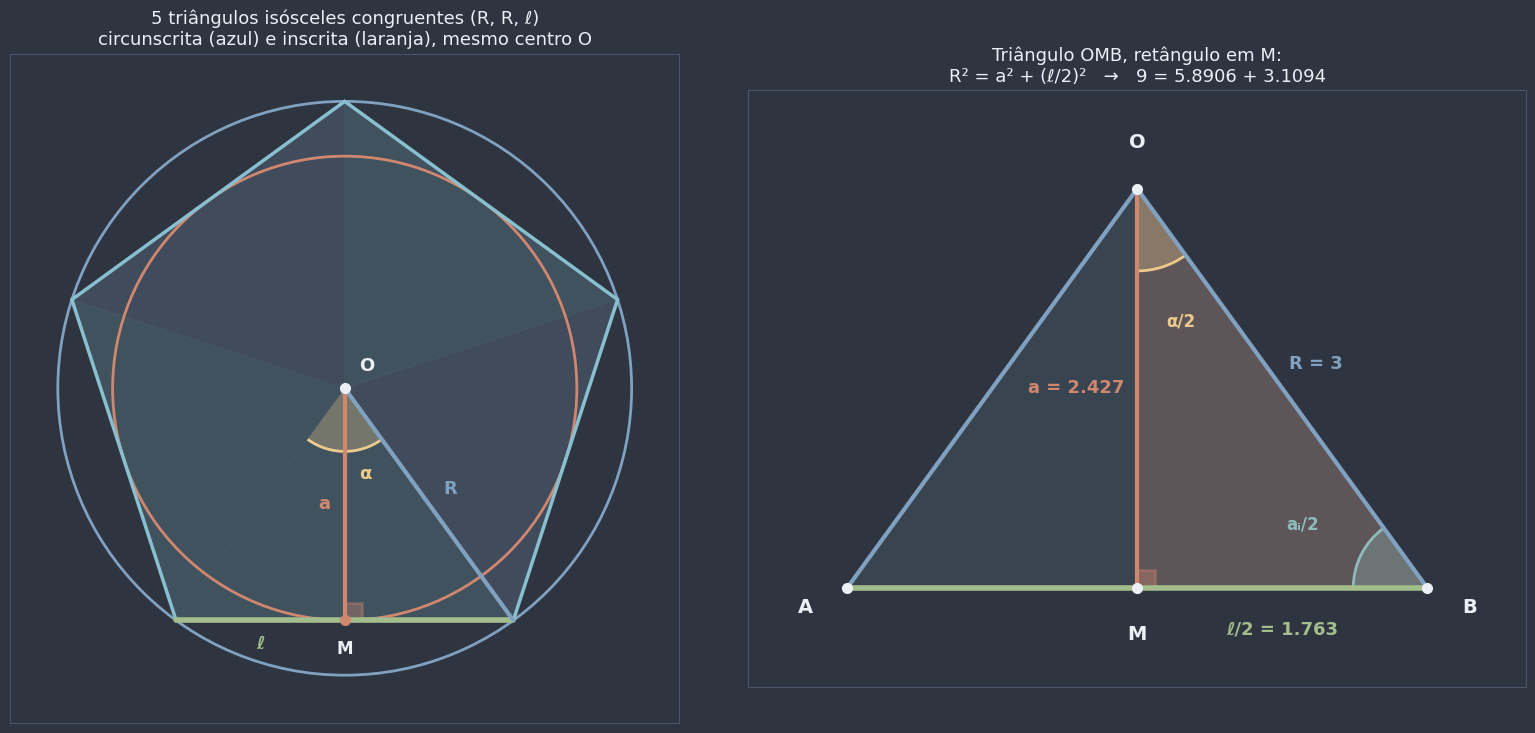

In [5]:
def desenhar_anatomia(ax, n: int, R: float, fatias: bool = True, tamanho: int = 12) -> None:
    """Polígono regular com as circunferências inscrita (laranja) e circunscrita (azul), o raio R até o vértice
    1, o apótema a até o ponto médio M do lado de baixo e o ângulo central α. Com `fatias=True`, pinta os n
    triângulos isósceles congruentes em cores alternadas."""
    V = vertices_regular(n, R)
    O = np.array([0.0, 0.0])
    a = apotema_de_R(n, R)
    M = ponto_medio(V[0], V[1])
    desenhar_circunferencia(ax, O, R, cor=COR_CIRCUNSCRITA, largura=2)
    desenhar_circunferencia(ax, O, a, cor=COR_INSCRITA, largura=2)
    if fatias:
        for k in range(n):
            ax.add_patch(Polygon([O, V[k], V[(k + 1) % n]], closed=True, alpha=0.22, edgecolor=NORD_LINHA, lw=1,
                                 facecolor=COR_POLIGONO if k % 2 == 0 else COR_SECUNDARIA, zorder=1))
    desenhar_poligono(ax, V, preencher=not fatias)
    desenhar_segmento(ax, V[0], V[1], cor=COR_LADO, largura=4)
    ax.text(*(0.75 * V[0] + 0.25 * V[1] - (0, 0.05 * R)), "ℓ", color=COR_LADO, fontsize=tamanho + 1,
            fontweight="bold", ha="center", va="top")
    desenhar_segmento(ax, O, V[1], cor=COR_RAIO, largura=3)
    rotular_segmento(ax, O, V[1], "R", cor=COR_RAIO, distancia=0.09 * R, longe_de=V[0], tamanho=tamanho + 1)
    desenhar_segmento(ax, O, M, cor=COR_APOTEMA, largura=3)
    ax.text(M[0] - 0.05 * R, M[1] / 2, "a", color=COR_APOTEMA, fontsize=tamanho + 1, fontweight="bold",
            ha="right", va="center")
    desenhar_setor(ax, M, 0, 90, raio=0.1 * R, cor=COR_APOTEMA)
    desenhar_arco(ax, O, V[0], V[1], raio=0.22 * R, cor=COR_CENTRAL)
    ax.text(0.05 * R, -0.3 * R, "α", color=COR_CENTRAL, fontsize=tamanho + 1, fontweight="bold", ha="left",
            va="center")
    desenhar_ponto(ax, O, cor=NORD_TEXTO)
    ax.text(0.05 * R, 0.06 * R, "O", color=NORD_TEXTO, fontsize=tamanho + 1, fontweight="bold")
    desenhar_ponto(ax, M, cor=COR_APOTEMA)
    rotular_fora(ax, M + (0, -0.001), "M", O, distancia=0.1 * R, tamanho=tamanho)


fig, (ax_e, ax_d) = plt.subplots(1, 2, figsize=(16, 7.4))
fig.patch.set_facecolor(NORD_FUNDO)
n_ex, R_ex = 5, 3.0
desenhar_anatomia(ax_e, n_ex, R_ex)
preparar_eixo(ax_e, [(-R_ex, -R_ex), (R_ex, R_ex)], margem=0.5)
ax_e.set_title("5 triângulos isósceles congruentes (R, R, ℓ)\ncircunscrita (azul) e inscrita (laranja), mesmo centro O",
               color=NORD_TEXTO, fontsize=13)

# O triângulo OAB ampliado, com o triângulo retângulo OMB
V = vertices_regular(n_ex, R_ex)
O, A, B = np.array([0.0, 0.0]), V[0], V[1]
M = ponto_medio(A, B)
a_ex, l_ex = apotema_de_R(n_ex, R_ex), lado_de_R(n_ex, R_ex)
ax_d.add_patch(Polygon([O, A, B], closed=True, facecolor=COR_POLIGONO, alpha=0.12, edgecolor="none"))
ax_d.add_patch(Polygon([O, M, B], closed=True, facecolor=COR_APOTEMA, alpha=0.25, edgecolor="none"))
desenhar_segmento(ax_d, A, B, cor=COR_LADO, largura=4)
desenhar_segmento(ax_d, O, A, cor=COR_RAIO, largura=3)
desenhar_segmento(ax_d, O, B, cor=COR_RAIO, largura=3)
desenhar_segmento(ax_d, O, M, cor=COR_APOTEMA, largura=3)
desenhar_setor(ax_d, M, 0, 90, raio=0.18, cor=COR_APOTEMA)
desenhar_arco(ax_d, O, M, B, raio=0.5, cor=COR_CENTRAL, rotulo="α/2", raio_rotulo=0.85, tamanho_fonte=12)
desenhar_arco(ax_d, B, O, A, raio=0.45, cor=COR_INTERNO, rotulo="aᵢ/2", raio_rotulo=0.85, tamanho_fonte=12)
rotular_segmento(ax_d, O, B, f"R = {R_ex:g}", cor=COR_RAIO, distancia=0.25, longe_de=A, tamanho=13)
rotular_segmento(ax_d, M, B, f"ℓ/2 = {l_ex / 2:.3f}", cor=COR_LADO, distancia=0.25, longe_de=O, tamanho=13)
ax_d.text(M[0] - 0.08, M[1] / 2, f"a = {a_ex:.3f}", color=COR_APOTEMA, fontsize=13, fontweight="bold",
          ha="right", va="center")
for P, nome in ((O, "O"), (A, "A"), (B, "B"), (M, "M")):
    desenhar_ponto(ax_d, P, cor=NORD_TEXTO)
    rotular_fora(ax_d, P, nome, (O + A + B) / 3, distancia=0.28, tamanho=14)
preparar_eixo(ax_d, [O, A, B], margem=0.6)
ax_d.set_title(f"Triângulo OMB, retângulo em M:\nR² = a² + (ℓ/2)²   →   {R_ex**2:g} = {a_ex**2:.4f} + {(l_ex / 2)**2:.4f}",
               color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

No triângulo ampliado aparecem as duas metades: $\overline{OM}$ divide o ângulo central $\alpha$ em duas metades $\frac{\alpha}{2}$ e $\overline{OB}$ divide o ângulo interno do polígono em duas metades $\frac{a_i}{2}$ (passo 2 da demonstração). No triângulo $OMB$, os ângulos somam $\frac{\alpha}{2} + \frac{a_i}{2} + 90° = 180°$, ou seja, $\alpha + a_i = 180°$: de novo, central e interno são suplementares, como externo e interno.

🕹️ **Widget interativo — anatomia do polígono regular:** escolha o número de lados $n$ (de 3 a 30) e o raio $R$. O desenho mostra o polígono com as duas circunferências, o raio (azul), o apótema (laranja), o lado de baixo (verde), o ângulo central (amarelo), o ângulo interno (verde-água) e o externo (roxo, entre o prolongamento de um lado e o lado seguinte). O painel recalcula os ângulos e as medidas e confere $R^2 = a^2 + (\ell/2)^2$ em tempo real. Observe o que acontece com a "folga" entre as duas circunferências quando $n$ cresce.

In [ ]:
def explorar_regular(n: int, R: float) -> None:
    V = vertices_regular(n, R)
    lado, a = lado_de_R(n, R), apotema_de_R(n, R)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 7.2), gridspec_kw={"width_ratios": [1.15, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_anatomia(ax, n, R, fatias=False, tamanho=11)
    # Ângulo interno no vértice 1 e ângulo externo entre o prolongamento de V0V1 e o lado V1V2
    desenhar_arco(ax, V[1], V[0], V[2], raio=0.16 * R, cor=COR_INTERNO)
    prolongamento = V[1] + 0.45 * R * (V[1] - V[0]) / np.linalg.norm(V[1] - V[0])
    desenhar_segmento(ax, V[1], prolongamento, cor=COR_EXTERNO, largura=1.8, estilo="--")
    desenhar_arco(ax, V[1], prolongamento, V[2], raio=0.24 * R, cor=COR_EXTERNO)
    preparar_eixo(ax, [(-5.2, -5.2), (5.2, 5.2)], margem=0.2)
    ax.set_title(f"Polígono regular de {n} lados, R = {R:g}", color=NORD_TEXTO, fontsize=13)

    itens = [
        (f"ângulo central α = 360°/{n} = {angulo_central(n):.2f}°", iguais(medir_angulo((0, 0), V[0], V[1]), angulo_central(n))),
        (f"ângulo externo a_e = 360°/{n} = {angulo_externo(n):.2f}°", True),
        (f"ângulo interno a_i = ({n} − 2)·180°/{n} = {angulo_interno(n):.2f}°", iguais(medir_angulo(V[1], V[0], V[2]), angulo_interno(n))),
        (f"a_i + a_e = {angulo_interno(n) + angulo_externo(n):.2f}°", True),
        (f"lado ℓ = {lado:.4f}   apótema a = {a:.4f}", True),
        (f"R² = {R**2:.4f}   a² + (ℓ/2)² = {a**2 + (lado / 2) ** 2:.4f}", iguais(R**2, a**2 + (lado / 2) ** 2)),
        (f"folga entre as circunferências: R − a = {R - a:.4f}", True),
        (f"a/R = {a / R:.4f}  (só depende de n: semelhança)", iguais(a / R, apotema_de_R(n, 1))),
    ]
    escrever_checklist(ax_lista, itens, "Medidas e conferências")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_regular,
    n=widgets.IntSlider(value=6, min=3, max=30, step=1, description="n:"),
    R=widgets.FloatSlider(value=4.0, min=1.0, max=5.0, step=0.5, description="R:"),
);

interactive(children=(IntSlider(value=6, description='n:', max=30, min=3), FloatSlider(value=4.0, description=…

Com $n$ grande, a folga $R - a$ quase some: as duas circunferências quase coincidem, e o polígono fica "espremido" entre elas. E a última linha do painel não muda quando você mexe só em $R$: a razão $a/R$ depende **só** de $n$ (semelhança).

⚠️ **Erro comum: confundir apótema com raio.** O **apótema** vai do centro ao **meio de um lado** (e é perpendicular a ele); o **raio** vai do centro a um **vértice**. Dica para não errar: "o apótema é a **altura** do triângulo $OAB$; o raio é o lado **oblíquo**". Por isso o apótema é sempre **menor** que o raio: é um cateto, e o raio é a hipotenusa.

⚠️ **Erro comum: achar que "equilátero" ou "equiângulo" basta.** O **losango** é equilátero e não é regular (os ângulos não são todos iguais); o **retângulo** é equiângulo e não é regular (os lados não são todos iguais). E, de fato, eles perdem uma das duas circunferências: o losango tem circunferência inscrita mas não circunscrita, e o retângulo tem circunscrita mas não inscrita (0411a e [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)). Veja abaixo.

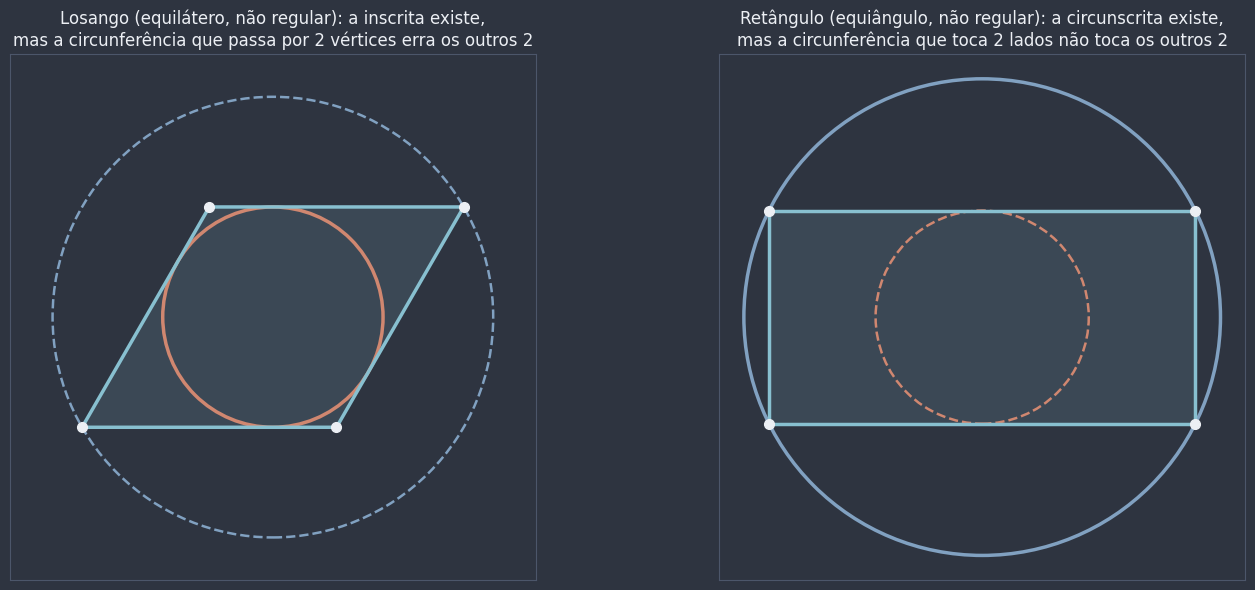

In [7]:
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor(NORD_FUNDO)

# Losango de lado 3 e ângulos de 60° e 120°: tem inscrita (centro no cruzamento das diagonais), não tem circunscrita
lado_l = 3.0
L = np.array([[0, 0], [lado_l, 0], [lado_l * 1.5, lado_l * math.sqrt(3) / 2], [lado_l / 2, lado_l * math.sqrt(3) / 2]])
centro_l = L.mean(axis=0)
r_l = lado_l * math.sqrt(3) / 4  # metade da altura do losango (a distância entre lados opostos)
desenhar_poligono(ax_l, L, cor=COR_POLIGONO)
desenhar_circunferencia(ax_l, centro_l, r_l, cor=COR_INSCRITA, largura=2.5)
desenhar_circunferencia(ax_l, centro_l, math.dist(centro_l, L[0]), cor=COR_CIRCUNSCRITA, largura=1.8, estilo="--")
for P in L:
    desenhar_ponto(ax_l, P, cor=NORD_TEXTO)
preparar_eixo(ax_l, [centro_l - 3, centro_l + 3], margem=0.1)
ax_l.set_title("Losango (equilátero, não regular): a inscrita existe,\nmas a circunferência que passa por 2 vértices erra os outros 2",
               color=NORD_TEXTO, fontsize=12)

# Retângulo 6 × 3: tem circunscrita, não tem inscrita
Q = np.array([[0, 0], [6, 0], [6, 3], [0, 3]], dtype=float)
centro_q = Q.mean(axis=0)
desenhar_poligono(ax_r, Q, cor=COR_POLIGONO)
desenhar_circunferencia(ax_r, centro_q, math.dist(centro_q, Q[0]), cor=COR_CIRCUNSCRITA, largura=2.5)
desenhar_circunferencia(ax_r, centro_q, 1.5, cor=COR_INSCRITA, largura=1.8, estilo="--")
for P in Q:
    desenhar_ponto(ax_r, P, cor=NORD_TEXTO)
preparar_eixo(ax_r, [centro_q - 3.6, centro_q + 3.6], margem=0.1)
ax_r.set_title("Retângulo (equiângulo, não regular): a circunscrita existe,\nmas a circunferência que toca 2 lados não toca os outros 2",
               color=NORD_TEXTO, fontsize=12)
plt.tight_layout()
plt.show()

🎯 **Aplicação prática — relógios e rosas dos ventos:** as 12 marcações das horas num mostrador de relógio são os vértices de um **dodecágono regular**: entre duas horas seguidas, o ângulo central é $\frac{360°}{12} = 30°$ (por isso, às 3h, os ponteiros formam $3 \cdot 30° = 90°$). Uma **rosa dos ventos** de 8 pontos (N, NE, L, SE, S, SO, O, NO) é um octógono regular, com $\frac{360°}{8} = 45°$ entre direções vizinhas; a de 16 pontos divide em $22{,}5°$.

📖 **Leitura complementar:** [Polígono regular](https://pt.wikipedia.org/wiki/Pol%C3%ADgono_regular) e [Apótema](https://pt.wikipedia.org/wiki/Ap%C3%B3tema)

**Pergunta de checagem:** um polígono regular tem ângulo externo de 24°. Quantos lados ele tem? Quanto mede o ângulo interno?

**Pergunta de checagem:** no octógono regular, quanto valem os ângulos central, interno e externo? Por que o central e o externo são iguais?

## 2. Os regulares "de bolso": triângulo, quadrado, hexágono, octógono e dodecágono

A relação $R^2 = a^2 + (\ell/2)^2$ tem três medidas e uma equação: falta **uma** informação para ligar $\ell$ e $a$ a $R$. Essa informação é o **ângulo** do triângulo $OMB$ no centro, que vale $\frac{\alpha}{2} = \frac{180°}{n}$. Para alguns valores de $n$, esse ângulo é de um **triângulo notável** de [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb), e tudo sai de cabeça. O objetivo aqui **não** é decorar o quadro do final da seção, e sim conseguir **refazer** cada linha.

### Triângulo equilátero ($n = 3$)

$\alpha = 120°$, então o ângulo em $O$ no triângulo $OMB$ é $60°$: $OMB$ é um **30°–60°–90°**, metade de um equilátero. O cateto oposto ao ângulo de 30° (o ângulo em $B$) é metade da hipotenusa:

$$a_3 = \frac{R}{2}, \qquad \frac{\ell_3}{2} = \frac{R\sqrt{3}}{2} \;\Longrightarrow\; \ell_3 = R\sqrt{3}.$$

(É o resultado de 0410a: no equilátero, o circuncentro divide a altura na razão $2 : 1$, então $R = 2r$.)

### Quadrado ($n = 4$)

$\alpha = 90°$, e o ângulo em $O$ é $45°$: $OMB$ é um **45°–45°–90°**, metade de um quadrado. Os catetos são iguais, $a_4 = \frac{\ell_4}{2}$, e a hipotenusa é $R = \frac{\ell_4}{2}\sqrt{2}$:

$$\ell_4 = R\sqrt{2}, \qquad a_4 = \frac{\ell_4}{2} = \frac{R\sqrt{2}}{2}.$$

(O lado do quadrado inscrito é a diagonal de um quadradinho de lado $R$, e o diâmetro $2R$ é a diagonal do quadrado: $2R = \ell_4 \sqrt{2}$.)

### Hexágono regular ($n = 6$)

$\alpha = 60°$. O triângulo $OAB$ é isósceles ($OA = OB = R$) com ângulo de 60° no vértice, então os ângulos da base somam $120°$ e cada um vale $60°$: $OAB$ é **equilátero**! Logo

$$\ell_6 = R, \qquad a_6 = \text{altura do equilátero de lado } R = \frac{R\sqrt{3}}{2}.$$

O hexágono regular é feito de **seis triângulos equiláteros**. Consequência prática: com o compasso aberto no raio, marcando 6 vezes o raio ao longo da circunferência, a volta **fecha** exatamente: é a construção clássica do hexágono (e, ligando vértices alternados, do triângulo equilátero).

### Dobrando o número de lados (a chave da seção 5)

Conhecendo $\ell_n$ e $R$, como obter o lado $\ell_{2n}$ do polígono com o **dobro** de lados? Prolongue o apótema $\overline{OM}$ do lado $\overline{AB}$ até cortar a circunferência no ponto $P$, o meio do arco $\overset{\frown}{AB}$. O novo polígono tem $P$ como vértice, e $\overline{AP}$ é um lado dele. O segmento $\overline{MP}$ é a **flecha** da corda $\overline{AB}$ ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)), e mede $R - a_n$.

- Pitágoras em $OMA$: $a_n = \sqrt{R^2 - \dfrac{\ell_n^2}{4}}$.
- Pitágoras em $AMP$ (catetos $\frac{\ell_n}{2}$ e $R - a_n$, hipotenusa $\ell_{2n}$):

$$\ell_{2n}^2 = \left(\frac{\ell_n}{2}\right)^2 + (R - a_n)^2 = \underbrace{\frac{\ell_n^2}{4} + a_n^2}_{R^2} + R^2 - 2Ra_n = 2R^2 - 2R\,a_n.$$

Trocando $a_n$ pela expressão acima ($2R \cdot a_n = R\sqrt{4R^2 - \ell_n^2}$):

$$\boxed{\;\ell_{2n} = \sqrt{2R^2 - R\sqrt{4R^2 - \ell_n^2}}\;}$$

Só Pitágoras, duas vezes. Aplicações imediatas:

- **octógono** (dobrando o quadrado, $\ell_4 = R\sqrt{2}$): $\ell_8^2 = 2R^2 - R\sqrt{4R^2 - 2R^2} = R^2(2 - \sqrt{2})$, então $\ell_8 = R\sqrt{2 - \sqrt{2}}$ e $a_8 = \frac{R}{2}\sqrt{2 + \sqrt{2}}$;
- **dodecágono** (dobrando o hexágono, $\ell_6 = R$): $\ell_{12}^2 = 2R^2 - R\sqrt{3R^2} = R^2(2 - \sqrt{3})$, então $\ell_{12} = R\sqrt{2 - \sqrt{3}}$ e $a_{12} = \frac{R(\sqrt{6} + \sqrt{2})}{4}$.

📌 **Definição formal (os regulares de bolso, em função de $R$):**

| $n$ | polígono | $\alpha$ | lado $\ell_n$ | apótema $a_n$ | $\ell_n$ ($R = 1$) | $a_n$ ($R = 1$) |
|---|---|---|---|---|---|---|
| 3 | triângulo equilátero | 120° | $R\sqrt{3}$ | $\frac{R}{2}$ | 1,7321 | 0,5000 |
| 4 | quadrado | 90° | $R\sqrt{2}$ | $\frac{R\sqrt{2}}{2}$ | 1,4142 | 0,7071 |
| 6 | hexágono | 60° | $R$ | $\frac{R\sqrt{3}}{2}$ | 1,0000 | 0,8660 |
| 8 | octógono | 45° | $R\sqrt{2 - \sqrt{2}}$ | $\frac{R}{2}\sqrt{2 + \sqrt{2}}$ | 0,7654 | 0,9239 |
| 12 | dodecágono | 30° | $R\sqrt{2 - \sqrt{3}}$ | $\frac{R(\sqrt{6} + \sqrt{2})}{4}$ | 0,5176 | 0,9659 |

e, para dobrar: $\ell_{2n} = \sqrt{2R^2 - R\sqrt{4R^2 - \ell_n^2}}$, com $a_n = \sqrt{R^2 - \ell_n^2/4}$.

**No código:** `lado_inscrito(n, R)` usa as fórmulas fechadas para $n = 3, 4, 6$ e, para os outros, **dobra** a partir delas com `dobrar_lado` (8 vem de 4; 12 de 6; 16 de 8; 24 de 12...). Se $n$ não vem de dobras de 3, 4 ou 6 (o pentágono, por exemplo), a função avisa com um `ValueError`. Tudo é conferido com a régua digital `lado_de_R` da seção 1.

In [8]:
def dobrar_lado(lado: float, R: float = 1.0) -> float:
    """Lado ℓ₂ₙ do polígono regular de 2n lados inscrito em λ(O, R), a partir do lado ℓₙ (Pitágoras duas vezes):
    ℓ₂ₙ = √(2R² − R·√(4R² − ℓₙ²))."""
    return math.sqrt(2 * R**2 - R * math.sqrt(4 * R**2 - lado**2))


def lado_inscrito(n: int, R: float = 1.0) -> float:
    """Lado do polígono regular de n lados inscrito em λ(O, R), só com Pitágoras e os triângulos notáveis:
    fórmulas fechadas para n = 3, 4 e 6 e, para os demais, dobras a partir delas."""
    fechadas = {3: R * math.sqrt(3), 4: R * math.sqrt(2), 6: R}
    if n in fechadas:
        return fechadas[n]
    if n % 2 == 0 and n > 6:
        return dobrar_lado(lado_inscrito(n // 2, R), R)
    raise ValueError(f"o lado do polígono de {n} lados não sai por dobras de 3, 4 ou 6 (use lado_de_R)")


def apotema_inscrito(n: int, R: float = 1.0) -> float:
    """Apótema do polígono regular de n lados inscrito em λ(O, R), por Pitágoras: a = √(R² − ℓ²/4)."""
    return math.sqrt(R**2 - lado_inscrito(n, R) ** 2 / 4)


for R in (1.0, 2.0, 5.5):
    for n in (3, 4, 6, 8, 12, 16, 24, 48, 96):
        assert iguais(lado_inscrito(n, R), lado_de_R(n, R)), f"lado errado para n = {n}"
        assert iguais(apotema_inscrito(n, R), apotema_de_R(n, R)), f"apótema errado para n = {n}"
    assert iguais(lado_inscrito(8, R), R * math.sqrt(2 - math.sqrt(2)))
    assert iguais(apotema_inscrito(8, R), R / 2 * math.sqrt(2 + math.sqrt(2)))
    assert iguais(lado_inscrito(12, R), R * math.sqrt(2 - math.sqrt(3)))
    assert iguais(apotema_inscrito(12, R), R * (math.sqrt(6) + math.sqrt(2)) / 4)
print("Fórmulas fechadas e dobras conferem com as coordenadas para n = 3, 4, 6, 8, 12, 16, 24, 48, 96.  ✓")
try:
    lado_inscrito(5)
except ValueError as erro:
    print("lado_inscrito(5):", erro)


def so_pitagoras(n: int) -> str:
    try:
        lado_inscrito(n)
        return "sim"
    except ValueError:
        return "não"


tabela_regulares = pd.DataFrame(
    [{"n": n, "α": angulo_central(n), "a_i": angulo_interno(n), "a_e": angulo_externo(n),
      "ℓ/R": lado_de_R(n, 1), "a/R": apotema_de_R(n, 1), "sai por dobras de 3, 4, 6?": so_pitagoras(n)}
     for n in range(3, 13)]
)
display(tabela_regulares.round(4))

Fórmulas fechadas e dobras conferem com as coordenadas para n = 3, 4, 6, 8, 12, 16, 24, 48, 96.  ✓
lado_inscrito(5): o lado do polígono de 5 lados não sai por dobras de 3, 4 ou 6 (use lado_de_R)


,n,α,a_i,a_e,ℓ/R,a/R,"sai por dobras de 3, 4, 6?"
0,3,120.0000,60.0000,120.0000,1.7321,0.5000,sim
1,4,90.0000,90.0000,90.0000,1.4142,0.7071,sim
2,5,72.0000,108.0000,72.0000,1.1756,0.8090,não
3,6,60.0000,120.0000,60.0000,1.0000,0.8660,sim
4,7,51.4286,128.5714,51.4286,0.8678,0.9010,não
5,8,45.0000,135.0000,45.0000,0.7654,0.9239,sim
6,9,40.0000,140.0000,40.0000,0.6840,0.9397,não
7,10,36.0000,144.0000,36.0000,0.6180,0.9511,não
8,11,32.7273,147.2727,32.7273,0.5635,0.9595,não
9,12,30.0000,150.0000,30.0000,0.5176,0.9659,sim


Na tabela, os polígonos com "sim" são exatamente os da forma $3 \cdot 2^k$ ou $4 \cdot 2^k$ (3, 4, 6, 8, 12): para eles, Pitágoras e os notáveis bastam. Os outros (5, 7, 9, 10, 11) têm lado e apótema bem definidos (a régua digital mede), mas a conta exige outra ferramenta: o **seno** ([`0505a_arcos_notaveis.ipynb`](../05_trigonometria/0505a_arcos_notaveis.ipynb)), ou, no caso do pentágono e do decágono, uma ideia esperta que aparece na curiosidade abaixo.

🕹️ **Widget interativo — o triângulo $OMB$ de cada regular:** escolha $n \in \{3, 4, 6, 8, 12\}$. A figura mostra o polígono inscrito na circunferência de raio 1 com o triângulo $OMB$ destacado e o ângulo $\frac{\alpha}{2}$ em $O$. Para $n = 8$ e $n = 12$, aparece também (tracejado) o polígono "pai", de $\frac{n}{2}$ lados, e o triângulo retângulo da **dobra**: catetos $\frac{\ell_{n/2}}{2}$ (meio lado do pai) e $R - a_{n/2}$ (a flecha), hipotenusa $\ell_n$.

In [9]:
EXPRESSOES = {
    3: ("ℓ₃ = R√3", "a₃ = R/2", "OMB é um 30°–60°–90° (ângulo de 60° em O)"),
    4: ("ℓ₄ = R√2", "a₄ = R√2/2", "OMB é um 45°–45°–90° (ângulo de 45° em O)"),
    6: ("ℓ₆ = R", "a₆ = R√3/2", "OAB é equilátero: 6 triângulos equiláteros"),
    8: ("ℓ₈ = R√(2 − √2)", "a₈ = (R/2)·√(2 + √2)", "dobra do quadrado: ℓ₈² = (ℓ₄/2)² + (R − a₄)²"),
    12: ("ℓ₁₂ = R√(2 − √3)", "a₁₂ = R(√6 + √2)/4", "dobra do hexágono: ℓ₁₂² = (ℓ₆/2)² + (R − a₆)²"),
}


def explorar_bolso(n: int) -> None:
    R = 1.0
    O = np.array([0.0, 0.0])
    dobra = n in (8, 12)
    # Na dobra, o polígono de n lados começa num vértice do pai, para que o meio do arco P = (0, −R) seja vértice
    V = vertices_regular(n, R, rotacao=-90 - 360 / n) if dobra else vertices_regular(n, R)
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 7.2), gridspec_kw={"width_ratios": [1.1, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    desenhar_circunferencia(ax, O, R, cor=COR_CIRCUNSCRITA, largura=2)
    desenhar_poligono(ax, V)
    if dobra:
        m = n // 2
        pai = vertices_regular(m, R)
        A, B = pai[0], pai[1]
        Mp, P = ponto_medio(A, B), np.array([0.0, -R])
        desenhar_poligono(ax, pai, cor=NORD_TEXTO_SEC, preencher=False, largura=1.5, estilo="--")
        ax.add_patch(Polygon([A, Mp, P], closed=True, facecolor=COR_AVISO, alpha=0.3, edgecolor="none"))
        desenhar_segmento(ax, A, Mp, cor=COR_LADO, largura=2.5, estilo="--")
        desenhar_segmento(ax, O, Mp, cor=COR_APOTEMA, largura=2.5)
        desenhar_segmento(ax, Mp, P, cor=COR_ALERTA, largura=3)
        desenhar_segmento(ax, A, P, cor=COR_LADO, largura=4)
        desenhar_setor(ax, Mp, 180, 90, raio=0.06, cor=COR_AVISO)
        rotular_segmento(ax, A, Mp, f"ℓ{m}/2", cor=COR_LADO, distancia=0.07, longe_de=O, tamanho=11)
        ax.text(0.04, (Mp[1] + P[1]) / 2, f"R − a{m}", color=COR_ALERTA, fontsize=11, fontweight="bold",
                va="center")
        ax.text(0.04, Mp[1] / 2, f"a{m}", color=COR_APOTEMA, fontsize=11, fontweight="bold", va="center")
        rotular_segmento(ax, A, P, f"ℓ{n}", cor=COR_LADO, distancia=0.08, longe_de=O, tamanho=12)
        for X, nome in ((A, "A"), (B, "B"), (Mp, "M"), (P, "P")):
            desenhar_ponto(ax, X, cor=NORD_TEXTO)
            rotular_fora(ax, X + (0.001, 0), nome, O, distancia=0.12, tamanho=12)
        titulo = f"{n} lados = dobra do polígono de {m} lados (tracejado)"
    else:
        A, B = V[0], V[1]
        M = ponto_medio(A, B)
        ax.add_patch(Polygon([O, M, B], closed=True, facecolor=COR_AVISO, alpha=0.3, edgecolor="none"))
        desenhar_segmento(ax, O, B, cor=COR_RAIO, largura=3)
        desenhar_segmento(ax, O, M, cor=COR_APOTEMA, largura=3)
        desenhar_segmento(ax, M, B, cor=COR_LADO, largura=4)
        desenhar_setor(ax, M, 0, 90, raio=0.07, cor=COR_AVISO)
        desenhar_arco(ax, O, M, B, raio=0.2, cor=COR_CENTRAL, rotulo=f"{angulo_central(n) / 2:g}°", raio_rotulo=0.32)
        rotular_segmento(ax, O, B, "R", cor=COR_RAIO, distancia=0.07, longe_de=M, tamanho=13)
        rotular_segmento(ax, M, B, "ℓ/2", cor=COR_LADO, distancia=0.08, longe_de=O, tamanho=12)
        ax.text(M[0] - 0.04, M[1] / 2, "a", color=COR_APOTEMA, fontsize=13, fontweight="bold", ha="right")
        for X, nome in ((O, "O"), (M, "M"), (B, "B")):
            desenhar_ponto(ax, X, cor=NORD_TEXTO)
            rotular_fora(ax, X + (0.001, 0.001), nome, (O + M + B) / 3, distancia=0.1, tamanho=12)
        titulo = f"{n} lados: triângulo OMB"
    preparar_eixo(ax, [(-1, -1), (1, 1)], margem=0.25)
    ax.set_title(titulo, color=NORD_TEXTO, fontsize=13)

    lado_expr, apot_expr, ideia = EXPRESSOES[n]
    itens = [
        (ideia, True),
        (f"{lado_expr}  →  {lado_inscrito(n):.4f} (medido: {lado_de_R(n, 1):.4f})", iguais(lado_inscrito(n), lado_de_R(n, 1))),
        (f"{apot_expr}  →  {apotema_inscrito(n):.4f} (medido: {apotema_de_R(n, 1):.4f})", iguais(apotema_inscrito(n), apotema_de_R(n, 1))),
        (f"ângulo central α = {angulo_central(n):g}°;  em O, no triângulo OMB: {angulo_central(n) / 2:g}°", True),
        (f"perímetro 2p = n·ℓ = {n * lado_inscrito(n):.4f}", True),
    ]
    escrever_checklist(ax_lista, itens, f"Polígono regular de {n} lados, R = 1")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_bolso, n=widgets.ToggleButtons(options=[3, 4, 6, 8, 12], value=6, description="n:"));

interactive(children=(ToggleButtons(description='n:', index=2, options=(3, 4, 6, 8, 12), value=6), Output()), …

⚠️ **Erro comum: "o apótema do hexágono é $\frac{R}{2}$"** (confundindo com o triângulo equilátero, em que $a_3 = \frac{R}{2}$) ou **"$\ell = R$ em qualquer polígono"**. Só no **hexágono** o lado é igual ao raio: no triângulo o lado é maior ($R\sqrt{3}$) e, a partir do heptágono, menor. Na dúvida, refaça o triângulo $OMB$.

🕵️ **Curiosidade histórica — o pentágono e a razão áurea:** o pentágono não está no quadro de bolso, mas também sai "limpo" com uma ideia esperta. No **decágono** regular, o triângulo $OAB$ tem ângulos $36°$, $72°$ e $72°$. A bissetriz do ângulo da base em $B$ corta $\overline{OA}$ num ponto $D$ e cria um triângulo $BDA$ **semelhante** a $OAB$ (caso AA de [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb): ângulos $36°$, $72°$, $72°$ de novo). Como o triângulo $ODB$ também é isósceles (dois ângulos de $36°$), $OD = BD = BA = \ell_{10}$, e a semelhança dá $\frac{\ell_{10}}{R} = \frac{R - \ell_{10}}{\ell_{10}}$, isto é, $\ell_{10}^2 = R(R - \ell_{10})$. Resolvendo a equação do 2º grau ([`0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb`](../01_conjuntos_e_funcoes/0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb)):

$$\ell_{10} = R \cdot \frac{\sqrt{5} - 1}{2} \approx 0{,}618 \, R,$$

o inverso da famosa **razão áurea** $\varphi = \frac{1 + \sqrt{5}}{2} \approx 1{,}618$. E Euclides mostrou que o lado do pentágono satisfaz $\ell_5^2 = \ell_6^2 + \ell_{10}^2 = R^2 + \ell_{10}^2$, que dá $\ell_5 \approx 1{,}1756 \, R$. A célula abaixo **verifica** as duas coisas numericamente (a dedução completa é o Desafio 9).

In [10]:
lado_10 = (math.sqrt(5) - 1) / 2  # R = 1
lado_5 = math.sqrt(1 + lado_10**2)  # Euclides: ℓ₅² = ℓ₆² + ℓ₁₀²
print(f"decágono:  (√5 − 1)/2 = {lado_10:.6f}   medido nas coordenadas = {lado_de_R(10, 1):.6f}")
print(f"pentágono: √(1 + ℓ₁₀²) = {lado_5:.6f}   medido nas coordenadas = {lado_de_R(5, 1):.6f}")
print(f"ℓ₁₀² = R·(R − ℓ₁₀)?  {lado_10**2:.6f} = {1 - lado_10:.6f}")
assert iguais(lado_10, lado_de_R(10, 1)) and iguais(lado_5, lado_de_R(5, 1))

decágono:  (√5 − 1)/2 = 0.618034   medido nas coordenadas = 0.618034
pentágono: √(1 + ℓ₁₀²) = 1.175571   medido nas coordenadas = 1.175571
ℓ₁₀² = R·(R − ℓ₁₀)?  0.381966 = 0.381966


🕵️ **Curiosidade histórica — régua e compasso:** os gregos sabiam construir com **régua e compasso** o triângulo equilátero, o quadrado, o pentágono e o hexágono regulares, e todos os que se obtêm deles **dobrando** o número de lados (exatamente o que a fórmula de dobra faz no papel). Por cerca de dois mil anos, ninguém conseguiu outros. Até que o jovem **Carl Friedrich Gauss**, no fim do século XVIII (em 1796, segundo os relatos mais comuns), mostrou que o polígono regular de **17 lados** também é construtível. Hoje, o **teorema de Gauss–Wantzel** diz exatamente quais valores de $n$ funcionam (o heptágono, por exemplo, não funciona). Fica como motivação para quem quiser ir além: [Polígono construtível](https://pt.wikipedia.org/wiki/Pol%C3%ADgono_construt%C3%ADvel).

### Resposta ao gancho: por que hexágonos?

Para cobrir o plano com cópias de **um único** polígono regular, encaixadas lado com lado e sem buracos, os ângulos internos que se encontram em cada vértice precisam somar exatamente $360°$. Então $\frac{360°}{a_i}$ tem que ser um número **inteiro** (a quantidade de cópias em volta de cada vértice). Com $a_i = \frac{(n - 2) \cdot 180°}{n}$:

$$\frac{360°}{a_i} = \frac{360 \cdot n}{(n - 2) \cdot 180} = \frac{2n}{n - 2}.$$

- $n = 3$: $a_i = 60°$ e $\frac{2n}{n - 2} = 6$ (seis triângulos em volta de cada vértice);
- $n = 4$: $a_i = 90°$ e $\frac{2n}{n - 2} = 4$;
- $n = 5$: $a_i = 108°$ e $\frac{2n}{n - 2} = \frac{10}{3} \approx 3{,}33$: **não fecha** (o buraco de 36° do gancho);
- $n = 6$: $a_i = 120°$ e $\frac{2n}{n - 2} = 3$;
- $n \geq 7$: $a_i$ fica entre $128{,}6°$ e $180°$, então $\frac{2n}{n - 2}$ fica entre 2 e 3 (sem chegar a nenhum dos dois): nunca é inteiro.

**Só triângulos, quadrados e hexágonos ladrilham o plano sozinhos.** A função `ladrilha` faz essa conta com números **inteiros** (sem arredondamento: $2n$ dividido por $n - 2$ tem resto zero?) e confere que, até $n = 1000$, só esses três passam.

In [11]:
def ladrilha(n: int) -> bool:
    """O polígono regular de n lados cobre o plano sozinho (lado com lado, sem buracos)? Só se 360°/a_i for
    inteiro, isto é, se 2n/(n − 2) for inteiro: a conta é feita com inteiros, sem arredondamento."""
    return (2 * n) % (n - 2) == 0


tabela_ladrilha = pd.DataFrame(
    [{"n": n, "a_i": angulo_interno(n), "360°/a_i": 360 / angulo_interno(n), "ladrilha?": "sim" if ladrilha(n) else "não"}
     for n in range(3, 13)]
)
display(tabela_ladrilha.round(3))
print("Até n = 1000, ladrilham:", [n for n in range(3, 1001) if ladrilha(n)])

,n,a_i,360°/a_i,ladrilha?
0,3,60.000,6.000,sim
1,4,90.000,4.000,sim
2,5,108.000,3.333,não
3,6,120.000,3.000,sim
4,7,128.571,2.800,não
5,8,135.000,2.667,não
6,9,140.000,2.571,não
7,10,144.000,2.500,não
8,11,147.273,2.444,não
9,12,150.000,2.400,não


Até n = 1000, ladrilham: [3, 4, 6]


🕹️ **Widget interativo — o ladrilhador:** escolha $n$. Se o polígono ladrilha ($n = 3, 4, 6$), aparece um pedaço do piso. Se não, o ladrilhador faz a melhor tentativa: um polígono no centro e uma cópia encostada em **cada** lado dele. Em cada vértice do polígono central, três cópias se encontram, somando $3 \cdot a_i$: no pentágono sobram $360° - 324° = 36°$ de **buraco**; do heptágono em diante, $3 \cdot a_i > 360°$ e as cópias vizinhas se **sobrepõem** (as regiões mais escuras). Os buracos e as sobreposições são marcados em vermelho.

In [12]:
def poligonos_ladrilho(n: int) -> list[np.ndarray]:
    """Peças de um ladrilhamento por triângulos, quadrados ou hexágonos de lado 1 (uma lista de polígonos)."""
    pecas = []
    if n == 4:
        pecas = [vertices_regular(4, 1 / math.sqrt(2), (i, j)) for i in range(-4, 5) for j in range(-4, 5)]
    elif n == 6:
        R = 1.0
        pecas = [vertices_regular(6, R, (1.5 * i, math.sqrt(3) * (j + (i % 2) / 2)), rotacao=0)
                 for i in range(-3, 4) for j in range(-3, 4)]
    elif n == 3:
        h = math.sqrt(3) / 2

        def ponto(i, j):
            return np.array([i + j / 2, j * h])

        for i in range(-8, 8):
            for j in range(-5, 6):
                pecas.append(np.array([ponto(i, j), ponto(i + 1, j), ponto(i, j + 1)]))
                pecas.append(np.array([ponto(i + 1, j), ponto(i + 1, j + 1), ponto(i, j + 1)]))
    return pecas


def explorar_ladrilho(n: int) -> None:
    fig, (ax, ax_lista) = plt.subplots(1, 2, figsize=(15.5, 7), gridspec_kw={"width_ratios": [1.15, 1]})
    fig.patch.set_facecolor(NORD_FUNDO)
    a_i = angulo_interno(n)
    cores = (COR_AVISO, COR_POLIGONO, COR_DESTAQUE)
    if ladrilha(n):
        for k, peca in enumerate(poligonos_ladrilho(n)):
            desenhar_poligono(ax, peca, cor=cores[k % 3] if n != 6 else COR_AVISO, opacidade=0.28, largura=1.8)
        preparar_eixo(ax, [(-3.5, -3.5), (3.5, 3.5)], margem=0)
        ax.set_title(f"n = {n}: o plano fica coberto, {2 * n // (n - 2)} peças em cada vértice", color=NORD_TEXTO,
                     fontsize=13)
    else:
        R = 1.0
        V = vertices_regular(n, R)
        desenhar_poligono(ax, V, cor=COR_AVISO, opacidade=0.35)
        meios = [ponto_medio(V[k], V[(k + 1) % n]) for k in range(n)]
        for M in meios:  # cópia "girada meia-volta" em torno do meio do lado: encosta no lado e fica do outro lado
            desenhar_poligono(ax, 2 * M - V, cor=COR_POLIGONO, opacidade=0.22, largura=1.6)
        sobra = 360 - 3 * a_i
        for k in range(n):
            M1, M2 = meios[k - 1], meios[k]
            E1, E2 = 2 * M1 - V[(k - 2) % n], 2 * M2 - V[(k + 2) % n]
            desenhar_arco(ax, V[k], E1, E2, raio=0.55, cor=COR_ALERTA, marcar_reto=False)
        rotulo = f"buraco de {sobra:.1f}° em cada vértice" if sobra > 0 else f"sobreposição de {-sobra:.1f}° em cada vértice"
        preparar_eixo(ax, [(-3.2, -3.2), (3.2, 3.2)], margem=0)
        ax.set_title(f"n = {n}: {rotulo}", color=NORD_TEXTO, fontsize=13)
    itens = [
        (f"ângulo interno a_i = {a_i:.2f}°", True),
        (f"360°/a_i = 2n/(n − 2) = {2 * n}/{n - 2} = {360 / a_i:.3f}", True),
        (f"360°/a_i é inteiro?  {'sim' if ladrilha(n) else 'não'}", ladrilha(n)),
        (f"3 peças em volta de um vértice: 3·a_i = {3 * a_i:.1f}°", math.isclose(3 * a_i, 360)),
        ("ladrilha o plano" if ladrilha(n) else "NÃO ladrilha o plano", ladrilha(n)),
    ]
    escrever_checklist(ax_lista, itens, f"Polígono regular de {n} lados")
    plt.tight_layout()
    plt.show()


widgets.interact(explorar_ladrilho, n=widgets.Dropdown(options=list(range(3, 11)), value=5, description="n:"));

interactive(children=(Dropdown(description='n:', index=2, options=(3, 4, 5, 6, 7, 8, 9, 10), value=5), Output(…

Entre os três que ladrilham, o hexágono tem uma vantagem: para o **mesmo perímetro**, ele cerca **mais área** que o quadrado e o triângulo (é o "mais redondo" dos três; o Desafio 10 compara as áreas). Para uma abelha, isso significa guardar mais mel gastando menos cera nas paredes. Que a estrutura de favo é a mais econômica possível ficou conhecido como a **conjectura do favo de mel**, e a literatura registra que o matemático **Thomas Hales** a demonstrou por volta de 1999. Mas cuidado com exageros: as abelhas não "calculam" nada, e há explicações físicas (a cera mole se acomoda) para o formato final das células.

🎯 **Aplicação prática — natureza e design:** hexágonos aparecem nos favos, nos flocos de neve, em cristais e no **grafeno** (uma folha de carbono com átomos nos vértices de hexágonos). Na engenharia, **porcas e parafusos** de cabeça sextavada (a chave encaixa em lados paralelos), as **placas de PARE** são octogonais (reconhecíveis até de costas), e pisos e azulejos usam exatamente os três ladrilhamentos regulares: triângulos, quadrados e hexágonos.

📖 **Leitura complementar:** [Proporção áurea](https://pt.wikipedia.org/wiki/Propor%C3%A7%C3%A3o_%C3%A1urea) (o pentágono e a razão áurea)

**Pergunta de checagem:** um hexágono regular tem lado 6 cm. Quanto mede o apótema? E o raio?

**Pergunta de checagem:** um quadrado está inscrito numa circunferência de raio 5 cm. Quanto medem o lado e o apótema?

## 3. Perímetro, área e polígonos circunscritos

### Perímetro

Os $n$ lados medem $\ell$ cada:

$$2p = n \cdot \ell \qquad \left(\text{e o semiperímetro é } p = \frac{n \cdot \ell}{2}\right).$$

### Área por decomposição: $S = p \cdot a$

Os $n$ triângulos congruentes $OAB$, $OBC$, ... da seção 1 cobrem o polígono sem sobrar nem faltar nada. Cada um tem **base** $\ell$ e **altura** $a$ (o apótema), então

$$S = n \cdot \frac{\ell \cdot a}{2} = \frac{n \cdot \ell}{2} \cdot a, \qquad\text{isto é,}\qquad \boxed{\;S = p \cdot a\;}\quad\text{(semiperímetro × apótema).}$$

É a **mesma** fórmula $S = p \cdot r$ de [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb), e pelo mesmo motivo: lá, o triângulo foi cortado em três triângulos com vértice no incentro, todos com altura $r$; aqui, o polígono regular é cortado em $n$ triângulos com vértice em $O$, todos com altura $a$, que é o raio da circunferência inscrita. (A área do triângulo como base × altura / 2 é a que vem sendo usada desde 0417a; a justificativa por equivalência de figuras fica para [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb).)

Exemplos, com as medidas da seção 2:
- **hexágono de lado $\ell$:** $p = 3\ell$ e $a = \frac{\ell\sqrt{3}}{2}$, então $S = 3\ell \cdot \frac{\ell\sqrt{3}}{2} = \frac{3\sqrt{3}}{2}\ell^2$: exatamente seis triângulos equiláteros de área $\frac{\sqrt{3}}{4}\ell^2$;
- **quadrado inscrito em $\lambda(O, R)$:** $p = 2R\sqrt{2}$ e $a = \frac{R\sqrt{2}}{2}$, então $S = 2R^2$ (a metade do quadrado de lado $2R$ que envolve a circunferência);
- **octógono inscrito:** $S = 4\ell_8 \cdot a_8 = 4R\sqrt{2 - \sqrt{2}} \cdot \frac{R}{2}\sqrt{2 + \sqrt{2}} = 2R^2\sqrt{(2 - \sqrt{2})(2 + \sqrt{2})} = 2\sqrt{2}\,R^2$.

### O polígono circunscrito à circunferência

Um polígono regular de $n$ lados está **circunscrito** à circunferência $\lambda(O, r)$ quando todos os seus lados são **tangentes** a ela ([`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb)). Nesse caso, a circunferência é a inscrita do polígono, e então o **apótema** do polígono circunscrito vale $r$.

Compare-o com o polígono regular de $n$ lados **inscrito** na mesma circunferência (raio $R = r$, apótema $a_n$). Os dois têm o mesmo $n$, então são **semelhantes** (seção 1), e a razão de semelhança é a razão entre os apótemas:

$$k = \frac{\text{apótema do circunscrito}}{\text{apótema do inscrito}} = \frac{r}{a_n} > 1.$$

Na prática, o circunscrito é uma **ampliação** do inscrito com centro em $O$ e razão $\frac{r}{a_n}$: cada vértice desliza para fora ao longo do próprio raio, e o ponto médio de cada lado vai parar exatamente sobre a circunferência (o ponto de tangência, no meio do arco). Com a semelhança ([`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)), os perímetros seguem a razão $k$ e as áreas, $k^2$:

$$2P_{\text{circ}} = 2p_{\text{insc}} \cdot \frac{r}{a_n}, \qquad S_{\text{circ}} = S_{\text{insc}} \cdot \left(\frac{r}{a_n}\right)^2.$$

**Exemplo:** o hexágono regular circunscrito à circunferência de raio 3. O inscrito tem $\ell_6 = 3$ e $a_6 = \frac{3\sqrt{3}}{2}$; a razão é $k = \frac{3}{3\sqrt{3}/2} = \frac{2}{\sqrt{3}}$. O lado do circunscrito é $L = 3 \cdot \frac{2}{\sqrt{3}} = 2\sqrt{3} \approx 3{,}46$, o perímetro é $6L = 12\sqrt{3} \approx 20{,}78$ e a área é $S = p \cdot a = 6\sqrt{3} \cdot 3 = 18\sqrt{3} \approx 31{,}18$.

### O sanduíche

Para o mesmo $n$, o polígono **inscrito** fica **dentro** da circunferência e o **circunscrito** fica **fora**. Então o comprimento da circunferência, qualquer que ele seja, fica espremido entre os dois perímetros:

$$2p_{\text{insc}} \;<\; C \;<\; 2P_{\text{circ}}.$$

(Que o perímetro de dentro é menor e o de fora é maior parece óbvio no desenho; uma prova rigorosa precisa da ideia de comprimento de curva, e é o tema da seção 4.) É **essa** a ideia que vai calcular $\pi$.

📌 **Definição formal (perímetro e área do polígono regular):** $2p = n \cdot \ell$ e $S = p \cdot a$. O polígono regular de $n$ lados circunscrito a $\lambda(O, r)$ é semelhante ao inscrito na razão $\frac{r}{a_n}$: perímetro × $\frac{r}{a_n}$, área × $\left(\frac{r}{a_n}\right)^2$.

📎 **Conexão:** quando $n$ cresce, $p$ se aproxima de **metade do comprimento da circunferência** e $a$ se aproxima de $R$, então $S = p \cdot a$ se aproxima de "meia circunferência vezes o raio". É assim que a **área do círculo** será obtida em [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb) (aqui, só o anúncio).

**No código:** `perimetro_regular` e `area_regular` ($S = p \cdot a$), conferidas com `area_por_coordenadas`, que soma as áreas dos $n$ triângulos $OV_kV_{k+1}$ por determinante ([`0305a_determinantes.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0305a_determinantes.ipynb)). Depois, `poligono_circunscrito` faz a ampliação e confere que o apótema dele é mesmo $r$.

In [13]:
def perimetro_regular(n: int, R: float = 1.0) -> float:
    """Perímetro 2p = n·ℓ do polígono regular de n lados inscrito em λ(O, R)."""
    return n * lado_de_R(n, R)


def area_regular(n: int, R: float = 1.0) -> float:
    """Área do polígono regular de n lados inscrito em λ(O, R): S = p·a (semiperímetro × apótema)."""
    return perimetro_regular(n, R) / 2 * apotema_de_R(n, R)


def area_por_coordenadas(vertices) -> float:
    """Área de um polígono convexo de vértices dados, somando os triângulos O V_k V_(k+1) com o centro O = média
    dos vértices: cada triângulo tem área |det[V_k − O, V_(k+1) − O]|/2 (0305a)."""
    V = np.asarray(vertices, dtype=float)
    O = V.mean(axis=0)
    return sum(abs(np.linalg.det(np.array([V[k] - O, V[(k + 1) % len(V)] - O]))) / 2 for k in range(len(V)))


def poligono_circunscrito(n: int, r: float = 1.0) -> np.ndarray:
    """Vértices do polígono regular de n lados CIRCUNSCRITO a λ(O, r): o inscrito ampliado, com centro em O,
    na razão r/aₙ (cada vértice desliza para fora ao longo do próprio raio)."""
    return vertices_regular(n, r) * (r / apotema_de_R(n, r))


for n in range(3, 13):
    for R in (1.0, 3.0):
        assert iguais(area_regular(n, R), area_por_coordenadas(vertices_regular(n, R))), f"S = p·a falhou em n = {n}"
        W = poligono_circunscrito(n, R)
        apotema_circ = math.dist((0, 0), ponto_medio(W[0], W[1]))
        perimetro_circ = sum(math.dist(W[k], W[(k + 1) % n]) for k in range(n))
        k = R / apotema_de_R(n, R)
        assert iguais(apotema_circ, R), "o apótema do circunscrito deveria ser r"
        assert iguais(perimetro_circ, perimetro_regular(n, R) * k), "perímetros fora da razão k"
        assert iguais(area_por_coordenadas(W), area_regular(n, R) * k**2), "áreas fora da razão k²"
        assert perimetro_regular(n, R) < perimetro_circ, "o inscrito deveria ter perímetro menor"
print("S = p·a confere com a soma dos triângulos por determinante (n de 3 a 12).  ✓")
print("Circunscrito: apótema = r, perímetro × r/aₙ e área × (r/aₙ)².  ✓")

for n, exata, texto in ((3, 3 * math.sqrt(3) / 4, "3√3/4·R²"), (4, 2, "2R²"), (6, 3 * math.sqrt(3) / 2, "3√3/2·R²"),
                        (8, 2 * math.sqrt(2), "2√2·R²")):
    print(f"n = {n:>2}: S = p·a = {area_regular(n, 1):.6f}   fórmula exata {texto:>9} = {exata:.6f}")

# O hexágono circunscrito à circunferência de raio 3
W = poligono_circunscrito(6, 3)
L = math.dist(W[0], W[1])
print(f"\nHexágono circunscrito a λ(O, 3): L = {L:.4f} (2√3 = {2 * math.sqrt(3):.4f}), 2p = {6 * L:.4f}, "
      f"S = {area_por_coordenadas(W):.4f} (18√3 = {18 * math.sqrt(3):.4f})")

S = p·a confere com a soma dos triângulos por determinante (n de 3 a 12).  ✓
Circunscrito: apótema = r, perímetro × r/aₙ e área × (r/aₙ)².  ✓
n =  3: S = p·a = 1.299038   fórmula exata  3√3/4·R² = 1.299038
n =  4: S = p·a = 2.000000   fórmula exata       2R² = 2.000000
n =  6: S = p·a = 2.598076   fórmula exata  3√3/2·R² = 2.598076
n =  8: S = p·a = 2.828427   fórmula exata    2√2·R² = 2.828427

Hexágono circunscrito a λ(O, 3): L = 3.4641 (2√3 = 3.4641), 2p = 20.7846, S = 31.1769 (18√3 = 31.1769)


Tudo confere, e as fórmulas exatas da teoria aparecem nos números: $2R^2$ no quadrado, $2\sqrt{2}R^2 \approx 2{,}83R^2$ no octógono.

A representação gráfica de $S = p \cdot a$, no hexágono. À esquerda, os seis triângulos de vértice $O$, cada um de base $\ell$ e altura $a$. À direita, os mesmos seis triângulos **desmontados** e enfileirados, alternando um "de pé" e um "de cabeça para baixo": eles formam um **paralelogramo** de base $3\ell = p$ (metade do perímetro) e altura $a$, cuja área é base × altura $= p \cdot a$.

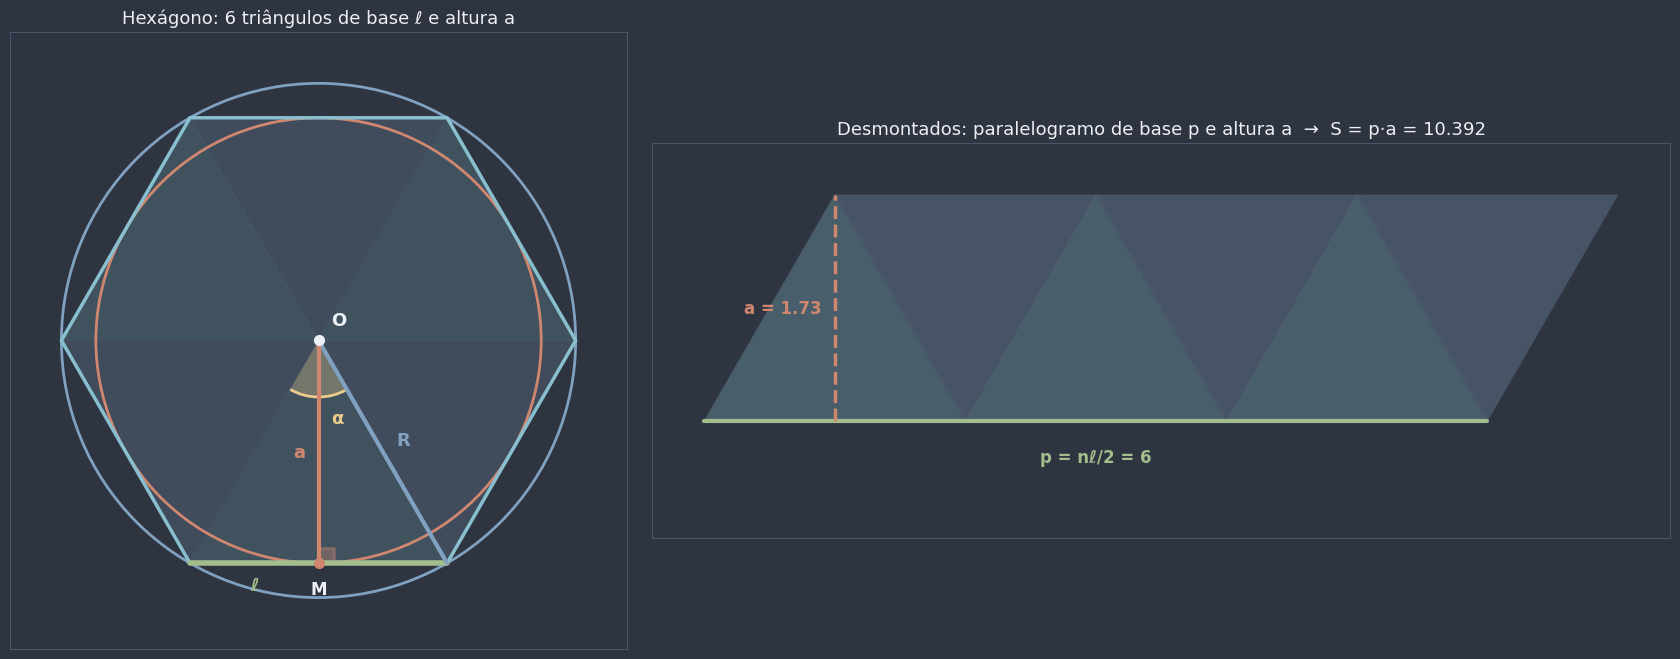

In [14]:
def desenhar_tira(ax, n: int, R: float, tamanho: int = 12) -> None:
    """Os n triângulos O V_k V_(k+1) do polígono regular, enfileirados alternando para cima e para baixo:
    juntos, eles formam (para n par) um paralelogramo de base p = nℓ/2 e altura a."""
    lado, a = lado_de_R(n, R), apotema_de_R(n, R)
    for k in range(n):
        x = k * lado / 2
        if k % 2 == 0:  # de pé: base embaixo
            T = [(x, 0), (x + lado, 0), (x + lado / 2, a)]
        else:  # de cabeça para baixo: base em cima
            T = [(x, a), (x + lado, a), (x + lado / 2, 0)]
        ax.add_patch(Polygon(T, closed=True, alpha=0.3, edgecolor=NORD_LINHA, lw=1.2,
                             facecolor=COR_POLIGONO if k % 2 == 0 else COR_SECUNDARIA))
    base = n * lado / 2
    desenhar_segmento(ax, (0, 0), (base, 0), cor=COR_LADO, largura=3)
    ax.text(base / 2, -0.12 * a, f"p = nℓ/2 = {base:.3g}", color=COR_LADO, fontsize=tamanho, fontweight="bold",
            ha="center", va="top")
    desenhar_segmento(ax, (lado / 2, 0), (lado / 2, a), cor=COR_APOTEMA, largura=2.5, estilo="--")
    ax.text(lado / 2 - 0.05 * lado, a / 2, f"a = {a:.3g}", color=COR_APOTEMA, fontsize=tamanho, fontweight="bold",
            ha="right", va="center")


fig, (ax_h, ax_t) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.6]})
fig.patch.set_facecolor(NORD_FUNDO)
R_h = 2.0
desenhar_anatomia(ax_h, 6, R_h)
preparar_eixo(ax_h, [(-R_h, -R_h), (R_h, R_h)], margem=0.4)
ax_h.set_title("Hexágono: 6 triângulos de base ℓ e altura a", color=NORD_TEXTO, fontsize=13)
desenhar_tira(ax_t, 6, R_h)
preparar_eixo(ax_t, [(0, -0.5), (3.5 * R_h, apotema_de_R(6, R_h))], margem=0.4)
ax_t.set_title(f"Desmontados: paralelogramo de base p e altura a  →  S = p·a = {area_regular(6, R_h):.3f}",
               color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — o sanduíche:** escolha $n$ (de 3 a 48). À esquerda, a circunferência de raio 1 com o polígono **inscrito** (azul-claro) e o **circunscrito** (roxo). À direita, os dois perímetros para todos os $n$, com a faixa entre eles pintada: a circunferência está sempre **dentro** dessa faixa. O painel mostra os perímetros, a média e as áreas. Veja a faixa se fechar enquanto $n$ cresce.

In [ ]:
def explorar_sanduiche(n: int) -> None:
    todos_n = np.arange(3, 49)
    insc = np.array([perimetro_regular(m) for m in todos_n])
    circ = np.array([perimetro_regular(m) / apotema_de_R(m, 1) for m in todos_n])
    p_in, p_out = perimetro_regular(n), perimetro_regular(n) / apotema_de_R(n, 1)

    fig = plt.figure(figsize=(17, 6.8))
    fig.patch.set_facecolor(NORD_FUNDO)
    ax = fig.add_axes([0.0, 0.05, 0.33, 0.85])
    ax_g = fig.add_axes([0.38, 0.12, 0.33, 0.76])
    ax_lista = fig.add_axes([0.74, 0.05, 0.26, 0.85])
    desenhar_poligono(ax, poligono_circunscrito(n, 1), cor=COR_CIRCUNSCRITO, opacidade=0.12)
    desenhar_circunferencia(ax, (0, 0), 1, cor=COR_CENTRAL, largura=2.5)
    desenhar_poligono(ax, vertices_regular(n, 1))
    preparar_eixo(ax, [(-1.25, -1.25), (1.25, 1.25)], margem=0.05)
    ax.set_title(f"n = {n}: inscrito < circunferência < circunscrito", color=NORD_TEXTO, fontsize=13)

    estilizar_eixo(ax_g)
    ax_g.fill_between(todos_n, insc, circ, color=COR_CENTRAL, alpha=0.2, label="a circunferência está aqui dentro")
    ax_g.plot(todos_n, insc, color=COR_POLIGONO, lw=2, label="perímetro do inscrito")
    ax_g.plot(todos_n, circ, color=COR_CIRCUNSCRITO, lw=2, label="perímetro do circunscrito")
    ax_g.plot([n, n], [p_in, p_out], color=COR_AVISO, lw=3)
    ax_g.plot([n, n], [p_in, p_out], "o", color=COR_AVISO, markersize=7)
    ax_g.set_ylim(5, 8)
    ax_g.set_xlabel("número de lados n", color=NORD_TEXTO)
    ax_g.set_ylabel("perímetro (raio 1)", color=NORD_TEXTO)
    ax_g.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, fontsize=10)

    itens = [
        (f"perímetro do inscrito: {p_in:.5f}", True),
        (f"perímetro do circunscrito: {p_out:.5f}", True),
        (f"largura da faixa: {p_out - p_in:.5f}", p_out - p_in < 0.01),
        (f"média dos dois: {(p_in + p_out) / 2:.5f}", True),
        (f"área do inscrito: {area_regular(n):.5f}", True),
        (f"área do circunscrito: {area_por_coordenadas(poligono_circunscrito(n, 1)):.5f}", True),
        (f"razão k = 1/aₙ = {1 / apotema_de_R(n, 1):.5f}", True),
    ]
    escrever_checklist(ax_lista, itens, "Raio 1 (✓ verde: faixa < 0,01)")
    plt.show()


widgets.interact(explorar_sanduiche, n=widgets.IntSlider(value=6, min=3, max=48, step=1, description="n:"));

interactive(children=(IntSlider(value=6, description='n:', max=48, min=3), Output()), _dom_classes=('widget-in…

A faixa se fecha, mas devagar: com 48 lados ela ainda tem largura de cerca de 0,013. A seção 5 vai acelerar isso **dobrando** o número de lados em vez de somar um a um. E repare que a média dos dois perímetros já fica muito perto de 6,28...

🎯 **Aplicação prática — cálculo de materiais:** um piso de **ladrilhos hexagonais** de lado 10 cm. Cada peça tem área $S = \frac{3\sqrt{3}}{2} \cdot 10^2 \approx 259{,}8 \text{ cm}^2$; para cobrir uma sala de 12 m² $= 120\,000$ cm², são necessárias cerca de $\frac{120\,000}{259{,}8} \approx 462$ peças (e, na prática, compra-se uns 10% a mais por causa dos cortes nas bordas). O mesmo $S = p \cdot a$ serve para bases e lajes hexagonais, coretos e torres de caixa-d'água octogonais, e lanternas e luminárias com faces regulares.

⚠️ **Erro comum: usar o perímetro inteiro onde a fórmula pede o semiperímetro.** $S = p \cdot a$ usa **metade** do perímetro (cada triângulo contribui com **metade** de base × altura). Quem usa $2p \cdot a$ obtém o **dobro** da área. A conferência por unidades (de 0417a) não pega esse erro, porque as duas expressões têm dimensão de comprimento²: o jeito de pegar é testar num caso conhecido, como o quadrado de lado 2 (apótema 1, $p = 4$, $S = 4$).

**Pergunta de checagem:** qual é a área de um octógono regular inscrito numa circunferência de raio 2? E a de um hexágono regular de lado 6?

**Pergunta de checagem:** o quadrado circunscrito a uma circunferência tem área de quantas vezes a do quadrado inscrito nela? (Use a razão $\frac{r}{a_4}$.)

## 4. O comprimento da circunferência e o número $\pi$

### A razão $C/d$ é a mesma em todas as circunferências

Duas circunferências quaisquer são **semelhantes**: uma é uma ampliação da outra, com razão $k = \frac{r'}{r}$ ([`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb)). Uma ampliação multiplica **todos** os comprimentos pela mesma razão: os lados dos polígonos inscritos, os perímetros deles e, portanto, o comprimento da própria circunferência. Então

$$\frac{C'}{C} = \frac{r'}{r} \quad\Longrightarrow\quad \frac{C'}{2r'} = \frac{C}{2r}.$$

A razão entre o comprimento e o diâmetro é **a mesma** para toda circunferência, de uma moeda até a órbita de um planeta. Essa constante ganhou um nome: a letra grega $\pi$ ("pi", inicial da palavra grega para **perímetro**).

📌 **Definição formal:** $\pi$ é a razão entre o comprimento e o diâmetro de qualquer circunferência:

$$\pi = \frac{C}{d}, \qquad\text{e portanto}\qquad C = \pi d = 2\pi r.$$

O número do gancho, aquele 6,28..., era $2\pi$: o comprimento da circunferência de **raio 1**.

### Mas o que é "comprimento" de uma linha curva?

A régua só mede segmentos. O sentido de "comprimento da circunferência" vem do sanduíche da seção 3: para cada $n$,

$$2p_{\text{insc}} < C < 2P_{\text{circ}},$$

e a diferença entre os dois perímetros **vai a zero** quando $n$ cresce (o widget da seção 3 mostrou a faixa se fechando). Existe **um único** número que fica entre os dois perímetros para todo $n$, e é esse número que chamamos de comprimento da circunferência. (A ferramenta que torna essa ideia rigorosa é o **limite**, do módulo de Cálculo.)

### Comprimento de um arco

Um arco de $\alpha$ graus ocupa a fração $\frac{\alpha}{360°}$ da circunferência (arcos de mesma medida, numa mesma circunferência, são congruentes, 0413a). Logo,

$$\boxed{\;\ell_{\text{arco}} = \frac{\alpha}{360°} \cdot 2\pi r\;}$$

Isso cumpre a promessa de [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb): a **medida angular** de um arco (em graus) não depende do raio, mas o **comprimento** (em cm) depende. Dois arcos de **60°** em circunferências de raios 6 e 12 têm a mesma medida angular, mas comprimentos $\frac{60}{360} \cdot 2\pi \cdot 6 = 2\pi \approx 6{,}28$ e $\frac{60}{360} \cdot 2\pi \cdot 12 = 4\pi \approx 12{,}57$.

📎 **Conexão:** a razão $\frac{\ell_{\text{arco}}}{r} = \frac{\alpha}{360°} \cdot 2\pi$ **não depende do raio**, só do ângulo. Ela é a definição do **radiano**, em [`0501a_arcos_e_angulos.ipynb`](../05_trigonometria/0501a_arcos_e_angulos.ipynb): $\alpha\,(\text{rad}) = \frac{\ell_{\text{arco}}}{r}$, e a volta completa mede $2\pi$ rad. Neste notebook, os ângulos ficam em graus.

🕵️ **Curiosidade histórica:** $\pi$ é **irracional**: não pode ser escrito como razão de dois inteiros (como $\sqrt{2}$, a "crise dos irracionais" de 0416a e de [`0103a_conjuntos_numericos.ipynb`](../01_conjuntos_e_funcoes/0103a_conjuntos_numericos.ipynb); a prova para $\pi$ é bem mais difícil e ficou só para o século XVIII, com Lambert). Mais ainda: ele é **transcendente**, isto é, não é raiz de nenhum polinômio com coeficientes inteiros, como provou **Ferdinand von Lindemann** em 1882. Por isso, frações como $\frac{22}{7} \approx 3{,}1429$ e $\frac{355}{113} \approx 3{,}1415929$ são só **aproximações** (a segunda, muito boa).

**No código:** `comprimento_circunferencia` e `comprimento_arco`, com `math.pi` (o valor da biblioteca, com 15 a 16 algarismos significativos). Depois, um **experimento de medição**: a lista `objetos` traz diâmetros de objetos circulares do dia a dia e um "comprimento medido" com fita métrica. Como não dá para medir de verdade aqui, o código **simula** a fita: usa $C = \pi d$ com um erro aleatório de até 1%, como o de uma medição caseira. Troque pelas suas próprias medidas na lista `minhas_medidas` e veja a razão $C/d$ aparecer.

In [16]:
def comprimento_circunferencia(r: float) -> float:
    """Comprimento da circunferência de raio r: C = 2πr."""
    return 2 * math.pi * r


def comprimento_arco(r: float, alfa_graus: float) -> float:
    """Comprimento do arco de α graus numa circunferência de raio r: (α/360°)·2πr."""
    return alfa_graus / 360 * comprimento_circunferencia(r)


for r in (0.5, 1, 6, 12, 1000):
    assert iguais(comprimento_arco(r, 360), comprimento_circunferencia(r)), "o arco de 360° é a circunferência"
    assert iguais(comprimento_circunferencia(r) / (2 * r), math.pi), "C/d deveria ser π"
assert iguais(comprimento_arco(6, 60), 2 * math.pi) and iguais(comprimento_arco(12, 60), 4 * math.pi)
print("Arco de 360° = C; C/d = π para todos os raios; arcos de 60° com r = 6 e r = 12: 2π e 4π.  ✓")
print(f"math.pi = {math.pi!r}   22/7 = {22 / 7:.10f}   355/113 = {355 / 113:.10f}")

# Experimento: diâmetros (cm) e comprimentos "medidos" com uma fita (simulados com erro de até ±1%)
gerador = np.random.default_rng(19)
objetos = {
    "moeda de R$ 1": 2.7, "lata de refrigerante": 6.6, "CD": 12.0, "prato": 25.0, "pizza grande": 35.0,
    "aro de basquete": 45.0, "roda de bicicleta": 66.0, "bambolê": 90.0,
}
medicoes = pd.DataFrame(
    [{"objeto": nome, "diâmetro d (cm)": d, "comprimento C medido (cm)": round(math.pi * d * (1 + gerador.uniform(-0.01, 0.01)), 1)}
     for nome, d in objetos.items()]
)
minhas_medidas = []  # acrescente pares (nome, diâmetro, comprimento) medidos por você, por exemplo ("copo", 7.5, 23.6)
for nome, d, C in minhas_medidas:
    medicoes.loc[len(medicoes)] = [nome, d, C]
medicoes["C/d"] = medicoes["comprimento C medido (cm)"] / medicoes["diâmetro d (cm)"]
display(medicoes.round(4))
print(f"média de C/d = {medicoes['C/d'].mean():.4f}   (π = {math.pi:.4f})")

Arco de 360° = C; C/d = π para todos os raios; arcos de 60° com r = 6 e r = 12: 2π e 4π.  ✓
math.pi = 3.141592653589793   22/7 = 3.1428571429   355/113 = 3.1415929204


,objeto,diâmetro d (cm),comprimento C medido (cm),C/d
0,moeda de R$ 1,2.7,8.5,3.1481
1,lata de refrigerante,6.6,20.9,3.1667
2,CD,12.0,37.5,3.1250
3,prato,25.0,77.8,3.1120
4,pizza grande,35.0,109.5,3.1286
5,aro de basquete,45.0,142.0,3.1556
6,roda de bicicleta,66.0,208.5,3.1591
7,bambolê,90.0,283.0,3.1444


média de C/d = 3.1424   (π = 3.1416)


Cada objeto dá um $C/d$ um pouco diferente (erros de medição), mas todos ficam em torno de 3,14, e a **média** chega ainda mais perto. É assim, medindo objetos, que povos antigos chegaram a valores como 3 ou $3\frac{1}{8}$; o salto de Arquimedes foi trocar a medição pelo **cálculo**.

A representação gráfica de $\pi$ como número de diâmetros: uma circunferência de **diâmetro 1** "desenrolada" sobre uma reta tem comprimento $\pi$. Cabem **três** diâmetros inteiros e sobra um pedacinho de cerca de 0,14 diâmetro.

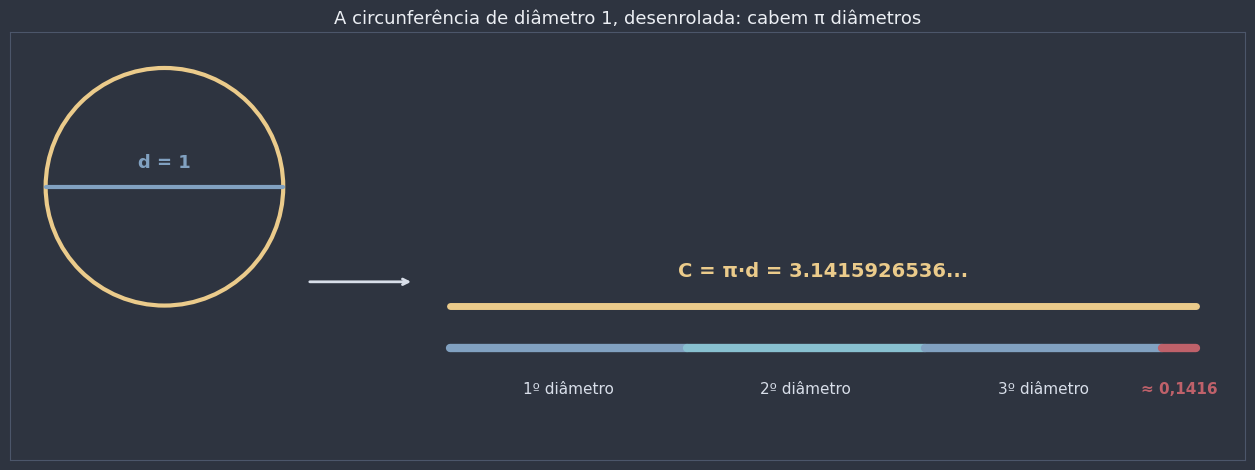

In [17]:
fig, ax = plt.subplots(figsize=(15, 4.8))
fig.patch.set_facecolor(NORD_FUNDO)
d = 1.0
centro = np.array([-0.9, d / 2])
desenhar_circunferencia(ax, centro, d / 2, cor=COR_CENTRAL, largura=3)
desenhar_segmento(ax, centro - (d / 2, 0), centro + (d / 2, 0), cor=COR_RAIO, largura=3)
ax.text(*(centro + (0, 0.08)), "d = 1", color=COR_RAIO, fontsize=13, fontweight="bold", ha="center")
ax.annotate("", xy=(0.15, 0.1), xytext=(-0.3, 0.1),
            arrowprops={"arrowstyle": "->", "color": NORD_TEXTO_SEC, "lw": 2})
# A circunferência desenrolada: π = 3 diâmetros + um resto
desenhar_segmento(ax, (0.3, 0), (0.3 + math.pi, 0), cor=COR_CENTRAL, largura=5)
for k in range(3):
    desenhar_segmento(ax, (0.3 + k, -0.18), (0.3 + k + 1, -0.18), cor=COR_RAIO if k % 2 == 0 else COR_POLIGONO,
                      largura=6)
    ax.text(0.3 + k + 0.5, -0.32, f"{k + 1}º diâmetro", color=NORD_TEXTO_SEC, fontsize=11, ha="center", va="top")
desenhar_segmento(ax, (3.3, -0.18), (0.3 + math.pi, -0.18), cor=COR_ALERTA, largura=6)
ax.text(0.3 + (3 + math.pi) / 2, -0.32, "≈ 0,1416", color=COR_ALERTA, fontsize=11, ha="center", va="top",
        fontweight="bold")
ax.text(0.3 + math.pi / 2, 0.12, f"C = π·d = {math.pi:.10f}...", color=COR_CENTRAL, fontsize=14,
        fontweight="bold", ha="center")
preparar_eixo(ax, [(-1.5, -0.6), (3.6, 1.1)], margem=0.05)
ax.set_title("A circunferência de diâmetro 1, desenrolada: cabem π diâmetros", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

🕹️ **Widget interativo — medida angular × comprimento:** dois sliders de raio ($r_1$ e $r_2$) e um de ângulo $\alpha$. As duas circunferências aparecem lado a lado, na mesma escala, com o arco de $\alpha$ graus destacado em cada uma. O painel compara: a **medida angular** é a mesma nas duas, o **comprimento** não; e a razão $\frac{\ell_{\text{arco}}}{r}$, que é o ângulo em radianos, de novo é igual nas duas.

In [18]:
def explorar_arco(r1: float, r2: float, alfa: float) -> None:
    fig, eixos = plt.subplots(1, 3, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1, 1.05]})
    fig.patch.set_facecolor(NORD_FUNDO)
    for ax, r, nome in ((eixos[0], r1, "r₁"), (eixos[1], r2, "r₂")):
        O = np.array([0.0, 0.0])
        desenhar_circunferencia(ax, O, r, cor=NORD_TEXTO_SEC, largura=1.5)
        if alfa > 0:
            ax.add_patch(Wedge(O, r, 0, alfa, facecolor=COR_CENTRAL, alpha=0.15, edgecolor="none"))
            ax.add_patch(Arc(O, 2 * r, 2 * r, theta1=0, theta2=alfa, color=COR_CENTRAL, lw=5))
        desenhar_segmento(ax, O, r * direcao(0), cor=COR_RAIO, largura=2.5)
        desenhar_segmento(ax, O, r * direcao(alfa), cor=COR_RAIO, largura=2.5)
        desenhar_setor(ax, O, 0, alfa, raio=min(1.0, 0.3 * r), cor=COR_CENTRAL, rotulo=f"{alfa:g}°",
                       raio_rotulo=min(1.0, 0.3 * r) + 0.6, marcar_reto=True)
        ax.text(r / 2, -0.25, f"{nome} = {r:g}", color=COR_RAIO, fontsize=12, fontweight="bold", ha="center",
                va="top")
        desenhar_ponto(ax, O, cor=NORD_TEXTO)
        preparar_eixo(ax, [(-8, -8), (8, 8)], margem=0.3)
        ax.set_title(f"arco de {alfa:g}°: comprimento {comprimento_arco(r, alfa):.3f}", color=NORD_TEXTO,
                     fontsize=13)
    l1, l2 = comprimento_arco(r1, alfa), comprimento_arco(r2, alfa)
    itens = [
        (f"medida angular: {alfa:g}° nas duas (não depende do raio)", True),
        (f"fração da volta: α/360° = {alfa / 360:.4f}", True),
        (f"comprimento com r₁ = {r1:g}: {l1:.4f}", True),
        (f"comprimento com r₂ = {r2:g}: {l2:.4f}", True),
        (f"comprimentos iguais?  {'sim' if iguais(l1, l2) else 'não'}", iguais(l1, l2)),
        (f"razão ℓ/r: {l1 / r1:.4f} e {l2 / r2:.4f} (radianos!)", iguais(l1 / r1, l2 / r2)),
    ]
    escrever_checklist(eixos[2], itens, "Medida × comprimento")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar_arco,
    r1=widgets.FloatSlider(value=3.0, min=1.0, max=7.5, step=0.5, description="r₁:"),
    r2=widgets.FloatSlider(value=6.0, min=1.0, max=7.5, step=0.5, description="r₂:"),
    alfa=widgets.IntSlider(value=60, min=0, max=360, step=5, description="α (graus):"),
);

interactive(children=(FloatSlider(value=3.0, description='r₁:', max=7.5, min=1.0, step=0.5), FloatSlider(value…

🎯 **Aplicações práticas — rodas, ponteiros e pistas:** a célula abaixo faz três contas do dia a dia.

- **Roda e odômetro:** uma roda de bicicleta aro 26 tem cerca de 66 cm de diâmetro. A cada volta, a bicicleta anda $C = \pi \cdot 0{,}66 \approx 2{,}07$ m, e em 1 km a roda dá cerca de 482 voltas. É isso que o velocímetro da bicicleta faz: conta voltas e multiplica por $C$ (por isso ele precisa saber o tamanho da roda).
- **Ponteiro de relógio:** a ponta de um ponteiro de minutos de 10 cm, em 20 minutos, percorre um arco de $\frac{20}{60} \cdot 360° = 120°$, isto é, $\frac{120}{360} \cdot 2\pi \cdot 10 \approx 20{,}94$ cm.
- **Pista de atletismo:** nas curvas, a raia de fora tem raio maior. Se cada raia tem 1,22 m de largura, numa curva de meia-volta a raia seguinte é mais comprida em $\pi \cdot 1{,}22 \approx 3{,}83$ m, **qualquer que seja o raio da curva** (a diferença $\pi(r + 1{,}22) - \pi r$ não depende de $r$). É por isso que, nas provas com curva, os atletas largam **escalonados**.

In [19]:
# Roda de bicicleta (aro 26, cerca de 66 cm de diâmetro)
C_roda = comprimento_circunferencia(0.66 / 2)
print(f"Roda: C = {C_roda:.4f} m por volta  →  {1000 / C_roda:.1f} voltas em 1 km")

# Ponteiro de minutos de 10 cm, em 20 minutos
alfa_ponteiro = 20 / 60 * 360
print(f"Ponteiro: {alfa_ponteiro:g}° em 20 min  →  a ponta percorre {comprimento_arco(10, alfa_ponteiro):.2f} cm")

# Pista: a diferença entre raias vizinhas numa meia-volta, para vários raios de curva
largura_raia = 1.22
for r in (30.0, 36.5, 50.0):
    diferenca = comprimento_arco(r + largura_raia, 180) - comprimento_arco(r, 180)
    print(f"Pista: curva de raio {r:>4} m  →  a raia seguinte é {diferenca:.3f} m mais longa na meia-volta")

Roda: C = 2.0735 m por volta  →  482.3 voltas em 1 km
Ponteiro: 120° em 20 min  →  a ponta percorre 20.94 cm
Pista: curva de raio 30.0 m  →  a raia seguinte é 3.833 m mais longa na meia-volta
Pista: curva de raio 36.5 m  →  a raia seguinte é 3.833 m mais longa na meia-volta
Pista: curva de raio 50.0 m  →  a raia seguinte é 3.833 m mais longa na meia-volta


⚠️ **Erros comuns:**
1. **Trocar raio por diâmetro:** $C = 2\pi r = \pi d$, mas **não** $\pi r$ nem $2\pi d$. Na dúvida, teste: numa circunferência de diâmetro 1, $C$ tem que ser pouco mais que 3.
2. **Usar 3,14 como se fosse o valor exato:** $\pi$ é irracional; 3,14 e $\frac{22}{7}$ são aproximações. No código, use sempre `math.pi`. (Num cálculo de cabeça, 3,14 é aceitável, desde que você saiba que é uma aproximação.)
3. **Confundir comprimento da circunferência com área do círculo:** comprimento é medida de **linha** (cm), área é medida de **região** (cm²). A fórmula da área do círculo chega só em [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb).

📖 **Leitura complementar:** [Pi](https://pt.wikipedia.org/wiki/Pi) e [Circunferência](https://pt.wikipedia.org/wiki/Circunfer%C3%AAncia)

**Pergunta de checagem:** um arco de 90° numa circunferência de raio 8 cm mede quanto?

**Pergunta de checagem:** uma roda de 60 cm de diâmetro dá quantas voltas em 100 m?

## 5. Calculando $\pi$ como Arquimedes

Por volta de 250 a.C., **Arquimedes** de Siracusa juntou as ideias das seções 2 a 4 num método para **calcular** $\pi$, e não apenas medi-lo. Com raio $R = 1$, a circunferência tem comprimento $2\pi$, então o **semiperímetro** de qualquer polígono inscrito é menor que $\pi$ e o de qualquer circunscrito é maior. Basta usar polígonos com muitos lados.

### Por baixo: os inscritos, dobrando a partir do hexágono

O ponto de partida é o hexágono, com $\ell_6 = R = 1$ e semiperímetro $p_6 = \frac{6 \cdot 1}{2} = 3$. A fórmula de dobra da seção 2, com $R = 1$,

$$\ell_{2n} = \sqrt{2 - \sqrt{4 - \ell_n^2}},$$

dá o lado do dodecágono, depois o do polígono de 24 lados, 48, 96... e o semiperímetro $p_n = \frac{n \cdot \ell_n}{2}$ de cada um:

| $n$ | 6 | 12 | 24 | 48 | 96 |
|---|---|---|---|---|---|
| $p_n$ (inscrito, $< \pi$) | 3,0000 | 3,1058 | 3,1326 | 3,1394 | 3,1410 |

### Por cima: os circunscritos, com duas médias

Pela seção 3, o circunscrito de $n$ lados tem semiperímetro $P_n = \frac{p_n}{a_n}$. Começando no hexágono, $P_6 = \frac{3}{\sqrt{3}/2} = 2\sqrt{3} \approx 3{,}4641$. Para dobrar os dois ao mesmo tempo, existe um par de fórmulas que só usa **médias**:

$$P_{2n} = \frac{2\,p_n\,P_n}{p_n + P_n} \quad(\text{média harmônica}), \qquad p_{2n} = \sqrt{p_n \cdot P_{2n}} \quad(\text{média geométrica}).$$

A dedução usa o teorema da bissetriz ([`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb)), semelhança (0415a) e uma relação métrica de 0416a; ela é o Desafio 8. Aqui, a gente só **aplica** a recorrência. Com 96 lados (quatro dobras a partir do hexágono), ela dá

$$3{,}14103 < \pi < 3{,}14271,$$

um intervalo que fica **dentro** dos limites históricos atribuídos a Arquimedes, também com 96 lados:

$$\frac{223}{71} \approx 3{,}14085 \;<\; \pi \;<\; \frac{22}{7} \approx 3{,}14286.$$

(Arquimedes fazia as contas à mão, com raízes quadradas aproximadas por frações, sempre arredondando "para o lado seguro"; por isso os limites dele são um pouco mais largos que os nossos.)

🕵️ **Curiosidade histórica:** com esse método, sem calculadora, Arquimedes garantiu duas casas decimais corretas ($\pi \approx 3{,}14$). Quase dois mil anos depois, o alemão-holandês **Ludolph van Ceulen** levou a ideia ao extremo: segundo os relatos, chegou a 20 casas decimais em 1596 e, mais tarde, a 35, com polígonos de cerca de $2^{62}$ lados, num trabalho de anos. Hoje, $\pi$ tem trilhões de casas calculadas por outros métodos, muito mais rápidos. Mas o princípio de Arquimedes, **trocar o curvo por pedaços retos cada vez menores**, é a semente do Cálculo.

**No código:** `semiperimetro_inscrito_ingenuo` aplica a fórmula de dobra tal como está acima; `cotas_arquimedes` aplica as duas médias. A célula confere que as duas maneiras dão os mesmos inscritos e que o intervalo de 96 lados contém `math.pi`.

In [20]:
def semiperimetro_inscrito_ingenuo(passos: int) -> list[tuple[int, float]]:
    """Semiperímetros p_n dos polígonos inscritos em λ(O, 1), do hexágono (n = 6) até n = 6·2^passos, com a
    fórmula de dobra "como está no papel": ℓ₂ₙ = √(2 − √(4 − ℓₙ²))."""
    n, lado = 6, 1.0
    historico = [(n, n * lado / 2)]
    for _ in range(passos):
        lado = math.sqrt(2 - math.sqrt(4 - lado**2))
        n *= 2
        historico.append((n, n * lado / 2))
    return historico


def cotas_arquimedes(passos: int) -> list[tuple[int, float, float]]:
    """Cotas (n, p_n, P_n) para π, com p_n e P_n os semiperímetros do inscrito e do circunscrito em λ(O, 1), do
    hexágono até n = 6·2^passos, pelas médias: P₂ₙ = 2pP/(p + P) e p₂ₙ = √(p·P₂ₙ)."""
    n, p, P = 6, 3.0, 2 * math.sqrt(3)
    historico = [(n, p, P)]
    for _ in range(passos):
        P = 2 * p * P / (p + P)
        p = math.sqrt(p * P)
        n *= 2
        historico.append((n, p, P))
    return historico


cotas = cotas_arquimedes(4)
ingenuo = semiperimetro_inscrito_ingenuo(4)
tabela_arquimedes = pd.DataFrame(
    [{"n": n, "p_n (inscrito)": p, "P_n (circunscrito)": P, "P_n − p_n": P - p, "erro de p_n": math.pi - p}
     for n, p, P in cotas]
)
display(tabela_arquimedes.round(6))

for (n, p, P), (_, p_ingenuo) in zip(cotas, ingenuo):
    assert iguais(p, p_ingenuo), "as duas maneiras deveriam dar o mesmo inscrito"
    assert iguais(p, perimetro_regular(n) / 2), "o inscrito deveria bater com as coordenadas"
    assert iguais(P, perimetro_regular(n) / 2 / apotema_de_R(n, 1)), "o circunscrito deveria bater com a seção 3"
    assert p < math.pi < P, "π deveria estar entre as cotas"
n96, p96, P96 = cotas[-1]
assert 223 / 71 < p96 < math.pi < P96 < 22 / 7
print(f"96 lados:  {p96:.5f} < π < {P96:.5f}   ⊂   223/71 = {223 / 71:.5f} < π < 22/7 = {22 / 7:.5f}  ✓")

,n,p_n (inscrito),P_n (circunscrito),P_n − p_n,erro de p_n
0,6,3.000000,3.464102,0.464102,0.141593
1,12,3.105829,3.215390,0.109562,0.035764
2,24,3.132629,3.159660,0.027031,0.008964
3,48,3.139350,3.146086,0.006736,0.002242
4,96,3.141032,3.142715,0.001683,0.000561


96 lados:  3.14103 < π < 3.14271   ⊂   223/71 = 3.14085 < π < 22/7 = 3.14286  ✓


A última coluna mostra o erro do inscrito caindo para cerca de **um quarto** a cada dobra: 0,14, 0,036, 0,0089, 0,0022, 0,00056. Dobrar o número de lados divide o lado por (quase) 2, e o erro acompanha o **quadrado** do lado.

⚠️ **Armadilha numérica (cuidado obrigatório):** e se continuarmos dobrando? Com 30 dobras, o polígono teria $6 \cdot 2^{30} \approx 6{,}4$ bilhões de lados, e a estimativa deveria ficar perfeita. Mas a fórmula $\ell_{2n} = \sqrt{2 - \sqrt{4 - \ell_n^2}}$ esconde uma armadilha: quando $\ell_n$ é pequeno, $\sqrt{4 - \ell_n^2}$ fica **muito perto de 2**, e a subtração $2 - \sqrt{4 - \ell_n^2}$ de dois números quase iguais joga fora os algarismos significativos. É o **cancelamento catastrófico**, o mesmo da fórmula de Herão nos triângulos-agulha de 0417a. O computador guarda cerca de 16 algarismos; quando $\ell_n^2$ fica menor que $10^{-16}$, a conta $4 - \ell_n^2$ dá **exatamente 4**, e o lado seguinte sai **zero**.

A saída é reescrever a fórmula sem a subtração, multiplicando e dividindo pelo **conjugado** (como na racionalização de denominadores):

$$\sqrt{2 - \sqrt{4 - \ell^2}} = \sqrt{\frac{\left(2 - \sqrt{4 - \ell^2}\right)\left(2 + \sqrt{4 - \ell^2}\right)}{2 + \sqrt{4 - \ell^2}}} = \sqrt{\frac{4 - (4 - \ell^2)}{2 + \sqrt{4 - \ell^2}}} = \frac{\ell}{\sqrt{2 + \sqrt{4 - \ell^2}}}.$$

No papel, as duas fórmulas são **a mesma**. No computador, a segunda só **soma** números positivos e não perde precisão. A célula abaixo roda as duas por 30 dobras, lado a lado.

**Lição:** uma fórmula correta na matemática pode ser ruim no computador.

,dobras,n,fórmula ingênua,fórmula estável
0,0,6,3,3
2,2,24,3.13262861328124,3.13262861328124
4,4,96,3.14103195089053,3.14103195089051
8,8,1536,3.14159046323676,3.14159046322805
10,10,6144,3.14159251658815,3.14159251669216
12,12,24576,3.14159264532122,3.14159264503369
14,14,98304,3.14159264532122,3.14159265305504
16,16,393216,3.14159366984943,3.14159265355637
18,18,1572864,3.1416086962248,3.1415926535877
20,20,6291456,3.14167426502176,3.14159265358966


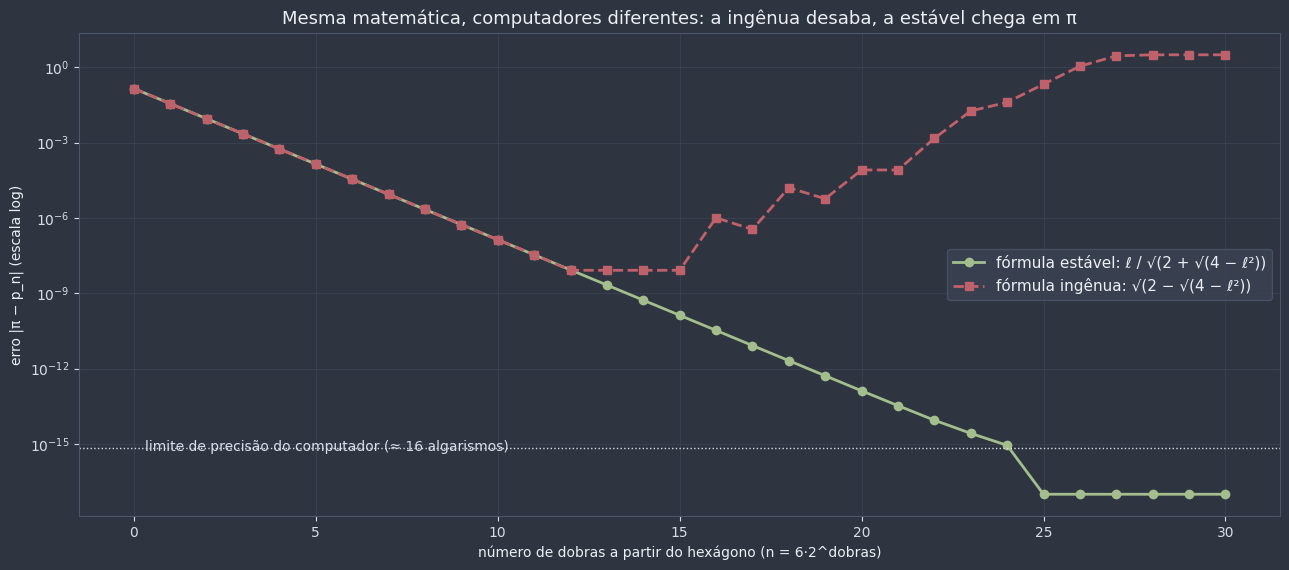

In [21]:
def semiperimetro_inscrito_estavel(passos: int) -> list[tuple[int, float]]:
    """Mesma recorrência de `semiperimetro_inscrito_ingenuo`, na forma sem subtração (pelo conjugado):
    ℓ₂ₙ = ℓₙ / √(2 + √(4 − ℓₙ²))."""
    n, lado = 6, 1.0
    historico = [(n, n * lado / 2)]
    for _ in range(passos):
        lado = lado / math.sqrt(2 + math.sqrt(4 - lado**2))
        n *= 2
        historico.append((n, n * lado / 2))
    return historico


DOBRAS = 30
ingenuo = semiperimetro_inscrito_ingenuo(DOBRAS)
estavel = semiperimetro_inscrito_estavel(DOBRAS)
comparacao = pd.DataFrame(
    [{"dobras": k, "n": n, "fórmula ingênua": p_i, "fórmula estável": p_e,
      "erro ingênua": abs(math.pi - p_i), "erro estável": abs(math.pi - p_e)}
     for k, ((n, p_i), (_, p_e)) in enumerate(zip(ingenuo, estavel))]
)
with pd.option_context("display.float_format", "{:.15g}".format):
    display(comparacao[["dobras", "n", "fórmula ingênua", "fórmula estável"]].iloc[[0, 2, 4, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30]])

assert ingenuo[-1][1] == 0.0, "a versão ingênua deveria ter desabado para zero"
assert abs(estavel[-1][1] - math.pi) < 1e-14, "a versão estável deveria chegar em π"

fig, ax = plt.subplots(figsize=(13, 5.8))
fig.patch.set_facecolor(NORD_FUNDO)
estilizar_eixo(ax)
piso = 1e-17  # erro zero não aparece em escala log: desenhamos no "piso"
ax.semilogy(comparacao["dobras"], np.maximum(comparacao["erro estável"], piso), "o-", color=COR_DESTAQUE, lw=2,
            label="fórmula estável: ℓ / √(2 + √(4 − ℓ²))")
ax.semilogy(comparacao["dobras"], np.maximum(comparacao["erro ingênua"], piso), "s--", color=COR_ALERTA, lw=2,
            label="fórmula ingênua: √(2 − √(4 − ℓ²))")
ax.axhline(2.2e-16 * math.pi, color=NORD_TEXTO_SEC, lw=1, linestyle=":")
ax.text(0.3, 4e-16, "limite de precisão do computador (≈ 16 algarismos)", color=NORD_TEXTO_SEC, fontsize=10, va="bottom")
ax.set_xlabel("número de dobras a partir do hexágono (n = 6·2^dobras)", color=NORD_TEXTO)
ax.set_ylabel("erro |π − p_n| (escala log)", color=NORD_TEXTO)
ax.set_title("Mesma matemática, computadores diferentes: a ingênua desaba, a estável chega em π", color=NORD_TEXTO,
             fontsize=13)
ax.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, fontsize=11, loc="center right")
plt.tight_layout()
plt.show()

Até umas 10 dobras, as duas fórmulas andam juntas, descendo em linha reta na escala log (cada dobra divide o erro por cerca de 4). Daí em diante, a ingênua **para de melhorar**: fica presa em $3{,}14159264$ por algumas dobras, depois **piora**, e a partir da dobra 22 dispara ($3{,}143$; $3{,}16$; $3{,}18$; $3{,}35$; $4{,}24$; $6$). Repare que esses valores passam de $\pi$, o que é **absurdo**: um polígono inscrito tem perímetro menor que a circunferência. São os arredondamentos ganhando dos algarismos certos. Da dobra 28 em diante, ela entrega **zero**, porque $4 - \ell^2$ virou exatamente 4. Enquanto isso, a estável chega a $3{,}141592653589793$ (todos os algarismos que o computador guarda) e fica lá.

🕹️ **Widget interativo — Arquimedes no computador:** o slider escolhe o número de dobras (de 0 a 30) e os botões escolhem a fórmula do inscrito (ingênua ou estável). À esquerda, o polígono inscrito e o circunscrito (até 6 dobras, depois disso eles se confundem com a circunferência e o desenho mostra só ela). No meio, as estimativas por baixo e por cima de todas as dobras até a escolhida, com a linha de $\pi$. O painel mostra o intervalo e quantos algarismos de $\pi$ estão garantidos. Leve a fórmula ingênua até 30 dobras.

In [ ]:
def algarismos_corretos(estimativa: float) -> int:
    """Quantos algarismos significativos de π a estimativa acerta (aproximadamente, pelo erro relativo)."""
    erro = abs(estimativa - math.pi) / math.pi
    return 16 if erro == 0 else max(0, int(-math.log10(erro)))


def explorar_arquimedes(dobras: int, formula: str) -> None:
    inscritos = (semiperimetro_inscrito_estavel if formula == "estável" else semiperimetro_inscrito_ingenuo)(dobras)
    cotas = cotas_arquimedes(dobras)
    n, p = inscritos[-1]
    P = cotas[-1][2]

    fig = plt.figure(figsize=(17, 6.6))
    fig.patch.set_facecolor(NORD_FUNDO)
    ax = fig.add_axes([0.0, 0.05, 0.3, 0.85])
    ax_g = fig.add_axes([0.36, 0.13, 0.34, 0.75])
    ax_lista = fig.add_axes([0.73, 0.05, 0.27, 0.85])
    desenhar_circunferencia(ax, (0, 0), 1, cor=COR_CENTRAL, largura=2)
    if dobras <= 6:
        desenhar_poligono(ax, poligono_circunscrito(n, 1), cor=COR_CIRCUNSCRITO, opacidade=0.1, largura=1.8)
        desenhar_poligono(ax, vertices_regular(n, 1), largura=1.8)
    preparar_eixo(ax, [(-1.18, -1.18), (1.18, 1.18)], margem=0.03)
    ax.set_title(f"n = {n:,} lados".replace(",", "."), color=NORD_TEXTO, fontsize=13)

    estilizar_eixo(ax_g)
    k = np.arange(dobras + 1)
    ax_g.plot(k, [c[2] for c in cotas], "o-", color=COR_CIRCUNSCRITO, lw=2, label="P (circunscrito, médias)")
    ax_g.plot(k, [x[1] for x in inscritos], "s-", color=COR_POLIGONO if formula == "estável" else COR_ALERTA, lw=2,
              label=f"p (inscrito, fórmula {formula})")
    ax_g.axhline(math.pi, color=COR_CENTRAL, lw=1.5, linestyle="--", label="π")
    ax_g.set_xlim(-0.5, 30.5)
    ax_g.set_ylim(2.95, 3.5)
    ax_g.set_xlabel("dobras", color=NORD_TEXTO)
    ax_g.legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, fontsize=10, loc="upper right")

    certos = min(algarismos_corretos(p), algarismos_corretos(P))
    itens = [
        (f"p (inscrito) = {p:.15f}", p <= math.pi),
        (f"P (circunscrito) = {P:.15f}", P >= math.pi),
        (f"π (math.pi)  = {math.pi:.15f}", True),
        (f"largura do intervalo P − p = {P - p:.3e}", P - p >= 0),
        (f"erro do inscrito: {abs(math.pi - p):.3e}", abs(math.pi - p) < 1e-3),
        (f"algarismos garantidos: {certos}", certos >= 3),
        ("o inscrito está entre 3 e P, como deve ser" if 3 <= p <= P else "absurdo: a fórmula ingênua desabou!",
         3 <= p <= P),
    ]
    escrever_checklist(ax_lista, itens, f"{dobras} dobras, fórmula {formula}")
    plt.show()


widgets.interact(
    explorar_arquimedes,
    dobras=widgets.IntSlider(value=4, min=0, max=30, step=1, description="dobras:"),
    formula=widgets.ToggleButtons(options=["estável", "ingênua"], value="estável", description="fórmula:"),
);

interactive(children=(IntSlider(value=4, description='dobras:', max=30), ToggleButtons(description='fórmula:',…

Com a fórmula ingênua e muitas dobras, o "inscrito" primeiro **ultrapassa** o circunscrito (sai do gráfico por cima) e depois **despenca** para zero (sai por baixo), dois absurdos: ele deveria ficar sempre entre 3 (o hexágono) e $P$. Enquanto isso, o circunscrito, calculado pelas médias, continua firme. As médias harmônica e geométrica não fazem subtrações, então também são estáveis.

🎯 **Aplicação prática — computação:** a tela de um computador não sabe desenhar curvas: ela desenha um **círculo** como um polígono com muitos lados pequenos (ou muitos pontinhos), exatamente a ideia de Arquimedes. E a armadilha numérica desta seção é um problema real em simulações de engenharia, física e finanças, que fazem bilhões de contas: escolher a fórmula **estável** pode ser a diferença entre um resultado certo e um lixo numérico.

📖 **Leitura complementar:** [Arquimedes](https://pt.wikipedia.org/wiki/Arquimedes) (biografia e a aproximação de $\pi$ com polígonos de 96 lados)

**Pergunta de checagem:** qual é o semiperímetro do dodecágono regular inscrito numa circunferência de raio 1? Por que ele é menor que $\pi$?

**Pergunta de checagem:** por que a fórmula $\ell_{2n} = \sqrt{2 - \sqrt{4 - \ell_n^2}}$ funciona bem com poucas dobras e mal com muitas, se ela é matematicamente correta?

### Fechando a história

Releia o caminho deste notebook: um polígono regular com **mais lados** fica **mais parecido** com a circunferência; o **perímetro** dele se aproxima do **comprimento** da circunferência; a razão entre esse comprimento e o diâmetro é sempre a mesma, $\pi$; e, espremendo $\pi$ entre inscritos e circunscritos, dá para calculá-lo com quantas casas quisermos. Em [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb), o mesmo argumento ($S = p \cdot a$, com $n$ cada vez maior) vai dar a **área do círculo**. É o primeiro encontro do curso com o **infinito**: um processo que nunca termina, mas que tem um destino bem definido. No módulo de Cálculo, esse destino vai se chamar **limite**.

## Resumo — cheat sheet

**Notação fixa:** $n$ lados; $\ell$ lado; $R$ raio (circunscrita); $a$ apótema (raio da inscrita); $2p$ perímetro, $p$ semiperímetro; $S$ área; $C$ comprimento da circunferência; $\alpha$ ângulo central.

| Conceito | Ideia-chave |
|---|---|
| **Polígono regular** | equilátero **e** equiângulo; inscritível e circunscritível, com o **mesmo centro** $O$ |
| **Ângulos** | central $\alpha = \frac{360°}{n}$; externo $a_e = \frac{360°}{n}$; interno $a_i = \frac{(n - 2) \cdot 180°}{n} = 180° - a_e$ |
| **Relação central** | $R^2 = a^2 + \left(\frac{\ell}{2}\right)^2$ (triângulo $OMB$, retângulo em $M$) |
| **Semelhança** | mesmo $n$ ⇒ semelhantes, na razão dos lados, dos raios e dos apótemas |
| **Triângulo** | $\ell_3 = R\sqrt{3}$, $a_3 = \frac{R}{2}$ |
| **Quadrado** | $\ell_4 = R\sqrt{2}$, $a_4 = \frac{R\sqrt{2}}{2}$ |
| **Hexágono** | $\ell_6 = R$, $a_6 = \frac{R\sqrt{3}}{2}$ (seis equiláteros) |
| **Dobrar os lados** | $\ell_{2n} = \sqrt{2R^2 - R\sqrt{4R^2 - \ell_n^2}}$; octógono $R\sqrt{2 - \sqrt{2}}$, dodecágono $R\sqrt{2 - \sqrt{3}}$ |
| **Ladrilhamento** | só $n = 3, 4, 6$ ($\frac{2n}{n - 2}$ inteiro) |
| **Perímetro e área** | $2p = n\ell$; $S = p \cdot a$ |
| **Circunscrito × inscrito** | mesmo $n$: semelhantes na razão $\frac{r}{a_n}$; perímetro × $\frac{r}{a_n}$, área × $\left(\frac{r}{a_n}\right)^2$ |
| **Sanduíche** | $2p_{\text{insc}} < C < 2P_{\text{circ}}$, e a diferença vai a zero |
| **Circunferência** | $\pi = \frac{C}{d}$ (constante, irracional); $C = 2\pi r = \pi d$ |
| **Arco** | $\ell_{\text{arco}} = \frac{\alpha}{360°} \cdot 2\pi r$ (medida angular ≠ comprimento) |
| **Arquimedes** | do hexágono, dobrando; $P_{2n} = \frac{2p_nP_n}{p_n + P_n}$, $p_{2n} = \sqrt{p_nP_{2n}}$; 96 lados ⇒ $\frac{223}{71} < \pi < \frac{22}{7}$ |
| **Numérico** | fórmulas iguais no papel podem ser diferentes no computador (cancelamento): $\sqrt{2 - \sqrt{4 - \ell^2}} = \frac{\ell}{\sqrt{2 + \sqrt{4 - \ell^2}}}$ |

**O fio condutor:** polígono regular → mais lados → quase uma circunferência → perímetro → comprimento $C$ → $\pi$ → (em Áreas) a área do círculo.

As figuras abaixo repetem as cores do notebook.

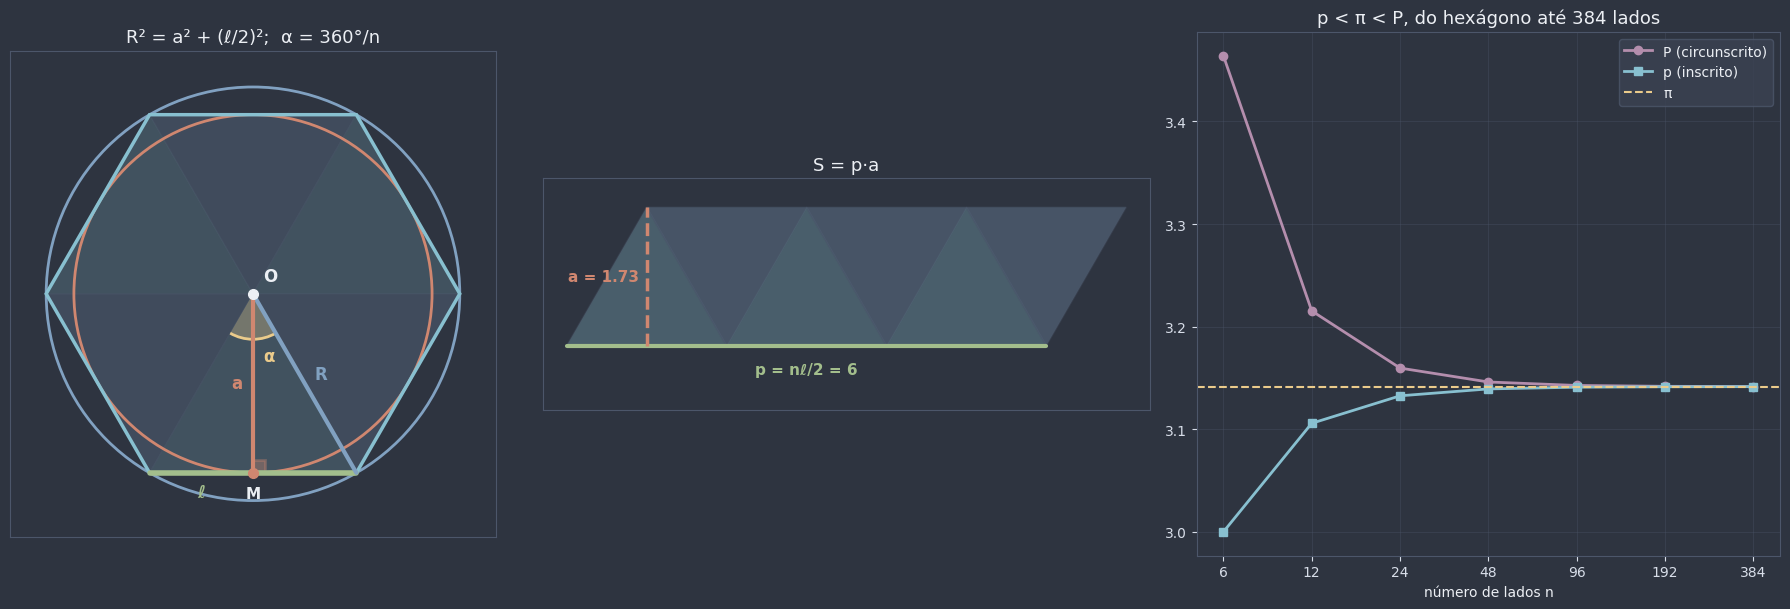

In [24]:
# Esta célula usa as ferramentas construídas ao longo do notebook (anatomia, tira e cotas de Arquimedes)
fig, eixos = plt.subplots(1, 3, figsize=(18, 6.2), gridspec_kw={"width_ratios": [1, 1.25, 1.2]})
fig.patch.set_facecolor(NORD_FUNDO)

desenhar_anatomia(eixos[0], 6, 2.0, tamanho=11)
preparar_eixo(eixos[0], [(-2, -2), (2, 2)], margem=0.35)
eixos[0].set_title("R² = a² + (ℓ/2)²;  α = 360°/n", color=NORD_TEXTO, fontsize=13)

desenhar_tira(eixos[1], 6, 2.0, tamanho=11)
preparar_eixo(eixos[1], [(0, -0.5), (7, 1.8)], margem=0.3)
eixos[1].set_title("S = p·a", color=NORD_TEXTO, fontsize=13)

estilizar_eixo(eixos[2])
cotas = cotas_arquimedes(6)
ns = [c[0] for c in cotas]
eixos[2].plot(range(len(ns)), [c[2] for c in cotas], "o-", color=COR_CIRCUNSCRITO, lw=2, label="P (circunscrito)")
eixos[2].plot(range(len(ns)), [c[1] for c in cotas], "s-", color=COR_POLIGONO, lw=2, label="p (inscrito)")
eixos[2].axhline(math.pi, color=COR_CENTRAL, lw=1.5, linestyle="--", label="π")
eixos[2].set_xticks(range(len(ns)))
eixos[2].set_xticklabels(ns)
eixos[2].set_xlabel("número de lados n", color=NORD_TEXTO)
eixos[2].legend(facecolor=NORD_PAINEL, edgecolor=NORD_LINHA, labelcolor=NORD_TEXTO, fontsize=10)
eixos[2].set_title("p < π < P, do hexágono até 384 lados", color=NORD_TEXTO, fontsize=13)
plt.tight_layout()
plt.show()

## Exercícios

**Básico**
1. Ângulos dos polígonos regulares (e o número de lados a partir de um ângulo).
2. Lado, apótema e área dos regulares de bolso, em função de $R$ e em função do lado.
3. Comprimento da circunferência e de arcos: rodas e ponteiros.

**Intermediário**

4. As suas próprias funções: vértices, lado, apótema, área, dobra e arco, conferidas com coordenadas.
5. O sanduíche em código: inscrito $< 2\pi R <$ circunscrito, e o menor $n$ com folga de 0,01.
6. Problemas de dois ou três passos: o hexágono de área dada, os dois quadrados e o octógono "cortado".
7. Pistas e odômetros.

**Desafio**

8. Arquimedes completo: as médias harmônica e geométrica e as cotas $\frac{223}{71} < \pi < \frac{22}{7}$.
9. O pentágono e a razão áurea, com construção por "compasso".
10. Para o mesmo perímetro, quem cerca mais área?

Gabarito completo com resolução comentada em [`0418b_poligonos_regulares_e_comprimento_da_circunferencia_gabarito.ipynb`](0418b_poligonos_regulares_e_comprimento_da_circunferencia_gabarito.ipynb).

### Básico

In [ ]:
# Exercício Básico 1: ângulos dos polígonos regulares.
# (a) Guarde em `angulos_ex1a` a tupla (central, interno, externo), em graus, do DECÁGONO regular (n = 10).
# (b) Um polígono regular tem ângulo EXTERNO de 24°. Guarde o número de lados em `n_ex1b`.
# (c) Um polígono regular tem ângulo INTERNO de 165°. Guarde o número de lados em `n_ex1c`.
#     (Dica: comece pelo externo.)
# (d) Guarde em `interno_ex1d` o ângulo interno do polígono do item (b).
angulos_ex1a = ...
n_ex1b = ...
n_ex1c = ...
interno_ex1d = ...

print(angulos_ex1a, n_ex1b, n_ex1c, interno_ex1d)

In [ ]:
# Verificação
assert angulos_ex1a is not ... and np.allclose(angulos_ex1a, (36, 144, 36)), (
    "Tente de novo, revise: central = externo = 360°/n e interno = (n − 2)·180°/n (seção 1 - O polígono regular e suas duas circunferências)."
)
assert n_ex1b is not ... and n_ex1b == 15, (
    "Tente de novo, revise: o externo vale 360°/n, então n = 360°/24° (seção 1 - O polígono regular e suas duas circunferências)."
)
assert n_ex1c is not ... and n_ex1c == 24, (
    "Tente de novo, revise: o externo é 180° − 165° = 15°, e n = 360°/15° (seção 1 - O polígono regular e suas duas circunferências)."
)
assert interno_ex1d is not ... and math.isclose(interno_ex1d, 156), (
    "Tente de novo, revise: interno = 180° − externo = 180° − 24° (seção 1 - O polígono regular e suas duas circunferências)."
)
print("Certo!")

In [ ]:
# Exercício Básico 2: os regulares de bolso (use as fórmulas da seção 2, com math.sqrt).
# (a) Um hexágono regular tem lado 6. Guarde o apótema em `apotema_ex2a` e a área em `area_ex2a`.
# (b) Um quadrado está inscrito numa circunferência de raio 5. Guarde o lado em `lado_ex2b`, o apótema em
#     `apotema_ex2b` e a área em `area_ex2b`.
# (c) Um triângulo equilátero está inscrito numa circunferência de raio 4. Guarde o lado em `lado_ex2c`, o apótema
#     em `apotema_ex2c` e a área em `area_ex2c` (pela fórmula S = p·a).
# (d) Um triângulo equilátero tem lado 9. Guarde o raio da circunferência circunscrita em `R_ex2d` e o da inscrita
#     (o apótema) em `apotema_ex2d`.
apotema_ex2a = ...
area_ex2a = ...
lado_ex2b = ...
apotema_ex2b = ...
area_ex2b = ...
lado_ex2c = ...
apotema_ex2c = ...
area_ex2c = ...
R_ex2d = ...
apotema_ex2d = ...

print(apotema_ex2a, area_ex2a, lado_ex2b, apotema_ex2b, area_ex2b, lado_ex2c, apotema_ex2c, area_ex2c, R_ex2d, apotema_ex2d)

In [ ]:
# Verificação
assert apotema_ex2a is not ... and math.isclose(apotema_ex2a, 3 * math.sqrt(3)), (
    "Tente de novo, revise: no hexágono, ℓ = R e a = R√3/2 (seção 2 - Os regulares de bolso)."
)
assert area_ex2a is not ... and math.isclose(area_ex2a, 54 * math.sqrt(3)), (
    "Tente de novo, revise: S = p·a, com p = 3ℓ = 18 (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert lado_ex2b is not ... and math.isclose(lado_ex2b, 5 * math.sqrt(2)) and apotema_ex2b is not ... and math.isclose(
    apotema_ex2b, 5 * math.sqrt(2) / 2), (
    "Tente de novo, revise: no quadrado, ℓ = R√2 e a = ℓ/2 (seção 2 - Os regulares de bolso)."
)
assert area_ex2b is not ... and math.isclose(area_ex2b, 50), (
    "Tente de novo, revise: a área do quadrado é ℓ² (ou p·a = 2R²) (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert lado_ex2c is not ... and math.isclose(lado_ex2c, 4 * math.sqrt(3)) and apotema_ex2c is not ... and math.isclose(
    apotema_ex2c, 2), (
    "Tente de novo, revise: no triângulo equilátero, ℓ = R√3 e a = R/2 (seção 2 - Os regulares de bolso)."
)
assert area_ex2c is not ... and math.isclose(area_ex2c, 12 * math.sqrt(3)), (
    "Tente de novo, revise: S = p·a, com p = 3ℓ/2 = 6√3 e a = 2 (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert R_ex2d is not ... and math.isclose(R_ex2d, 3 * math.sqrt(3)) and apotema_ex2d is not ... and math.isclose(
    apotema_ex2d, 3 * math.sqrt(3) / 2), (
    "Tente de novo, revise: de ℓ = R√3 sai R = ℓ/√3, e a = R/2 (seção 2 - Os regulares de bolso)."
)
print("Certo!")

In [ ]:
# Exercício Básico 3: comprimento da circunferência e de arcos (use math.pi).
# (a) Guarde em `C_ex3a` o comprimento da circunferência de raio 8 cm.
# (b) Guarde em `arco_ex3b` o comprimento de um arco de 90° nessa mesma circunferência.
# (c) Uma roda de 60 cm de DIÂMETRO rola sem escorregar. Guarde em `voltas_ex3c` quantas voltas ela dá em 100 m.
# (d) A ponta de um ponteiro de minutos de 10 cm anda durante 20 minutos. Guarde em `ponta_ex3d` o comprimento,
#     em cm, do caminho que ela percorre.
# (e) Um arco de 45° mede 3π cm. Guarde o raio da circunferência em `raio_ex3e`.
C_ex3a = ...
arco_ex3b = ...
voltas_ex3c = ...
ponta_ex3d = ...
raio_ex3e = ...

print(C_ex3a, arco_ex3b, voltas_ex3c, ponta_ex3d, raio_ex3e)

In [ ]:
# Verificação
assert C_ex3a is not ... and math.isclose(C_ex3a, 16 * math.pi), (
    "Tente de novo, revise: C = 2πr (seção 4 - O comprimento da circunferência e o número π)."
)
assert arco_ex3b is not ... and math.isclose(arco_ex3b, 4 * math.pi), (
    "Tente de novo, revise: ℓ_arco = (α/360°)·2πr (seção 4 - O comprimento da circunferência e o número π)."
)
assert voltas_ex3c is not ... and math.isclose(voltas_ex3c, 100 / (0.6 * math.pi)), (
    "Tente de novo, revise: cada volta anda C = π·d = π·0,6 m; trabalhe em metros (seção 4 - O comprimento da circunferência e o número π)."
)
assert ponta_ex3d is not ... and math.isclose(ponta_ex3d, 20 * math.pi / 3), (
    "Tente de novo, revise: em 20 min o ponteiro gira 20/60 de volta = 120° (seção 4 - O comprimento da circunferência e o número π)."
)
assert raio_ex3e is not ... and math.isclose(raio_ex3e, 12), (
    "Tente de novo, revise: (45/360)·2πr = 3π; isole r (seção 4 - O comprimento da circunferência e o número π)."
)
print("Certo!")

### Intermediário

In [ ]:
# Exercício Intermediário 4: as suas próprias funções.
# Complete as funções abaixo SEM usar as do notebook (vertices_regular, lado_de_R, apotema_de_R, area_regular,
# dobrar_lado, comprimento_arco). Pode usar math, numpy e a função direcao(angulo_em_graus).
# (a) vertices_regular_ex4(n, R): array n × 2 com os vértices do polígono regular de n lados inscrito em λ(O, R),
#     O = (0, 0) (qualquer rotação serve).
# (b) lado_ex4(n, R): a distância entre dois vértices consecutivos de vertices_regular_ex4(n, R).
# (c) apotema_ex4(n, R): por Pitágoras, a partir de R e de lado_ex4(n, R).
# (d) area_regular_ex4(n, R): S = p·a.
# (e) dobrar_lado_ex4(lado, R): o lado do polígono de 2n lados, a partir do lado do polígono de n lados.
# (f) comprimento_arco_ex4(r, alfa_graus): o comprimento do arco de α graus.
def vertices_regular_ex4(n: int, R: float) -> np.ndarray:
    return ...


def lado_ex4(n: int, R: float) -> float:
    return ...


def apotema_ex4(n: int, R: float) -> float:
    return ...


def area_regular_ex4(n: int, R: float) -> float:
    return ...


def dobrar_lado_ex4(lado: float, R: float) -> float:
    return ...


def comprimento_arco_ex4(r: float, alfa_graus: float) -> float:
    return ...


print(lado_ex4(6, 1), apotema_ex4(6, 1), area_regular_ex4(6, 1), dobrar_lado_ex4(1, 1), comprimento_arco_ex4(1, 180))

In [ ]:
# Verificação (contra medições diretas em coordenadas, para n de 3 a 20)
for n_v in range(3, 21):
    for R_v in (1.0, 3.5):
        V_v = vertices_regular_ex4(n_v, R_v)
        assert V_v is not ... and len(V_v) == n_v and all(iguais(math.dist((0, 0), P), R_v) for P in V_v), (
            "Tente de novo, revise: os n vértices ficam em λ(O, R), separados por 360°/n (seção 1 - O polígono regular e suas duas circunferências)."
        )
        assert all(iguais(math.dist(V_v[k], V_v[(k + 1) % n_v]), lado_de_R(n_v, R_v)) for k in range(n_v)), (
            "Tente de novo, revise: vértices consecutivos devem estar à distância ℓ (ângulos 360°/n em sequência) (seção 1 - O polígono regular e suas duas circunferências)."
        )
        assert lado_ex4(n_v, R_v) is not ... and iguais(lado_ex4(n_v, R_v), lado_de_R(n_v, R_v)), (
            "Tente de novo, revise: o lado é math.dist entre os vértices 0 e 1 (seção 1 - O polígono regular e suas duas circunferências)."
        )
        assert apotema_ex4(n_v, R_v) is not ... and iguais(apotema_ex4(n_v, R_v), apotema_de_R(n_v, R_v)), (
            "Tente de novo, revise: a = √(R² − (ℓ/2)²) (seção 1 - O polígono regular e suas duas circunferências)."
        )
        assert area_regular_ex4(n_v, R_v) is not ... and iguais(
            area_regular_ex4(n_v, R_v), area_por_coordenadas(vertices_regular(n_v, R_v))), (
            "Tente de novo, revise: S = p·a, com p = n·ℓ/2 (semiperímetro!) (seção 3 - Perímetro, área e polígonos circunscritos)."
        )
        assert dobrar_lado_ex4(lado_de_R(n_v, R_v), R_v) is not ... and iguais(
            dobrar_lado_ex4(lado_de_R(n_v, R_v), R_v), lado_de_R(2 * n_v, R_v)), (
            "Tente de novo, revise: ℓ₂ₙ = √(2R² − R·√(4R² − ℓₙ²)) (seção 2 - Os regulares de bolso)."
        )
for r_v, alfa_v in ((1, 360), (6, 60), (12, 60), (10, 120), (2.5, 45)):
    assert comprimento_arco_ex4(r_v, alfa_v) is not ... and iguais(comprimento_arco_ex4(r_v, alfa_v), alfa_v / 360 * 2 * math.pi * r_v), (
        "Tente de novo, revise: ℓ_arco = (α/360°)·2πr (seção 4 - O comprimento da circunferência e o número π)."
    )
print("Certo!")

In [ ]:
# Exercício Intermediário 5: o sanduíche em código (raio R = 1, então C = 2π).
# (a) Guarde em `sanduiche_ok_ex5` o valor True se, para TODO n de 3 a 200, valer
#     perímetro do inscrito < 2π < perímetro do circunscrito, e False caso contrário.
#     (Use perimetro_regular(n) e, para o circunscrito, perimetro_regular(n) / apotema_de_R(n, 1), da seção 3.)
# (b) Guarde em `n_min_ex5` o MENOR n para o qual os DOIS perímetros diferem de 2π por menos de 0,01.
sanduiche_ok_ex5 = ...
n_min_ex5 = ...

print(sanduiche_ok_ex5, n_min_ex5)

In [ ]:
# Verificação
assert sanduiche_ok_ex5 is not ... and sanduiche_ok_ex5 is True, (
    "Tente de novo, revise: teste as duas desigualdades para cada n de range(3, 201) e use all(...) (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert n_min_ex5 is not ... and n_min_ex5 == 46, (
    "Tente de novo, revise: procure o primeiro n em que 2π − (inscrito) < 0,01 E (circunscrito) − 2π < 0,01; "
    "é o circunscrito que demora mais (seção 3 - Perímetro, área e polígonos circunscritos)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 6: problemas de dois ou três passos.
# (a) Um hexágono regular tem área 54√3. Guarde o lado em `lado_ex6a`, o raio em `R_ex6a` e o apótema em
#     `apotema_ex6a`. (Dica: S = (3√3/2)·ℓ².)
# (b) Numa mesma circunferência, um quadrado está inscrito e outro está circunscrito. Guarde em `razao_ex6b` a razão
#     (área do circunscrito)/(área do inscrito).
# (c) De um quadrado de lado 10, cortam-se os quatro cantos (triângulos retângulos isósceles de catetos x) de modo
#     que sobre um OCTÓGONO REGULAR. Guarde x em `corte_ex6c` e o lado do octógono em `lado_octogono_ex6c`.
#     (Dica: o lado do octógono é a hipotenusa x√2 do canto e também o que sobra do lado do quadrado, 10 − 2x.)
lado_ex6a = ...
R_ex6a = ...
apotema_ex6a = ...
razao_ex6b = ...
corte_ex6c = ...
lado_octogono_ex6c = ...

print(lado_ex6a, R_ex6a, apotema_ex6a, razao_ex6b, corte_ex6c, lado_octogono_ex6c)

In [ ]:
# Verificação
assert lado_ex6a is not ... and math.isclose(lado_ex6a, 6) and R_ex6a is not ... and math.isclose(R_ex6a, 6), (
    "Tente de novo, revise: (3√3/2)·ℓ² = 54√3 dá ℓ² = 36; no hexágono, R = ℓ (seção 2 - Os regulares de bolso)."
)
assert apotema_ex6a is not ... and math.isclose(apotema_ex6a, 3 * math.sqrt(3)), (
    "Tente de novo, revise: no hexágono, a = ℓ√3/2 (seção 2 - Os regulares de bolso)."
)
assert razao_ex6b is not ... and math.isclose(razao_ex6b, 2), (
    "Tente de novo, revise: a razão de semelhança é k = r/a₄ = √2, e as áreas seguem k² (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert corte_ex6c is not ... and math.isclose(corte_ex6c, 10 / (2 + math.sqrt(2))), (
    "Tente de novo, revise: resolva x√2 = 10 − 2x (seção 2 - Os regulares de bolso)."
)
assert lado_octogono_ex6c is not ... and math.isclose(lado_octogono_ex6c, 10 * (math.sqrt(2) - 1)), (
    "Tente de novo, revise: o lado do octógono é x√2, com o x do item anterior (seção 2 - Os regulares de bolso)."
)
print("Certo!")

In [ ]:
# Exercício Intermediário 7: pistas e odômetros.
# Uma pista tem duas retas de 100 m e duas curvas em semicircunferência de raio 30 m (na raia de dentro).
# (a) Guarde em `pista_ex7a` o comprimento total da raia de dentro, em metros.
# (b) A raia seguinte corre 1,2 m mais para fora (raio 31,2 m nas curvas; as retas não mudam). Guarde em
#     `diferenca_ex7b` quantos metros ela tem A MAIS que a raia de dentro, numa volta completa.
# (c) Refaça o item (b) para uma pista com curvas de raio 50 m (e as mesmas retas) e guarde em `diferenca_ex7c`.
#     A diferença mudou?
# (d) O odômetro de uma bicicleta com roda de 66 cm de diâmetro contou 1000 voltas. Guarde em `distancia_ex7d` a
#     distância percorrida, em QUILÔMETROS.
pista_ex7a = ...
diferenca_ex7b = ...
diferenca_ex7c = ...
distancia_ex7d = ...

print(pista_ex7a, diferenca_ex7b, diferenca_ex7c, distancia_ex7d)

In [ ]:
# Verificação
assert pista_ex7a is not ... and math.isclose(pista_ex7a, 200 + 60 * math.pi), (
    "Tente de novo, revise: duas semicircunferências de raio 30 formam uma circunferência inteira, 2π·30 (seção 4 - O comprimento da circunferência e o número π)."
)
assert diferenca_ex7b is not ... and math.isclose(diferenca_ex7b, 2 * math.pi * 1.2), (
    "Tente de novo, revise: só as curvas mudam: 2π·31,2 − 2π·30 (seção 4 - O comprimento da circunferência e o número π)."
)
assert diferenca_ex7c is not ... and math.isclose(diferenca_ex7c, 2 * math.pi * 1.2), (
    "Tente de novo, revise: 2π·51,2 − 2π·50 = 2π·1,2: a diferença NÃO depende do raio (seção 4 - O comprimento da circunferência e o número π)."
)
assert distancia_ex7d is not ... and math.isclose(distancia_ex7d, 0.66 * math.pi), (
    "Tente de novo, revise: 1000 voltas de π·0,66 m, convertidas para km (÷ 1000) (seção 4 - O comprimento da circunferência e o número π)."
)
print("Certo!")

### Desafio

In [ ]:
# Exercício Desafio 8: Arquimedes completo.
# Com R = 1, sejam pₙ e Pₙ os SEMIperímetros do polígono regular de n lados inscrito e do circunscrito.
# Partindo do hexágono (p₆ = 3, P₆ = 2√3), as dobras seguem as médias
#     P₂ₙ = 2·pₙ·Pₙ/(pₙ + Pₙ)   (harmônica)   e   p₂ₙ = √(pₙ·P₂ₙ)   (geométrica, com o P NOVO).
# (a) Complete cotas_ex8(passos), que devolve a lista [(n, p, P), ...] do hexágono até n = 6·2^passos.
#     Não use a função cotas_arquimedes do notebook.
# (b) Guarde em `p96_ex8` e `P96_ex8` as cotas para 96 lados.
# (c) Guarde em `passos_ex8c` o MENOR número de dobras para o qual P − p < 1e-10.
# (d) (No papel, sem verificação automática.) Demonstre as duas médias. Roteiro: no circunscrito, a bissetriz do
#     ângulo central corta o meio lado tₙ = Pₙ/n; use o teorema da bissetriz (0414a) para obter t₂ₙ; depois, use a
#     relação métrica c² = a·m (0416a) no triângulo inscrito na semicircunferência para obter o inscrito de 2n lados.
def cotas_ex8(passos: int) -> list[tuple[int, float, float]]:
    return ...


p96_ex8 = ...
P96_ex8 = ...
passos_ex8c = ...

print(p96_ex8, P96_ex8, passos_ex8c)

In [ ]:
# Verificação
lista_v = cotas_ex8(8)
assert lista_v is not ... and len(lista_v) == 9 and all(
    n_a == n_b and iguais(p_a, p_b) and iguais(P_a, P_b) for (n_a, p_a, P_a), (n_b, p_b, P_b) in zip(lista_v, cotas_arquimedes(8))), (
    "Tente de novo, revise: primeiro o P novo (harmônica), depois o p novo com esse P (geométrica); n dobra a cada passo (seção 5 - Calculando π como Arquimedes)."
)
assert p96_ex8 is not ... and P96_ex8 is not ... and 223 / 71 < p96_ex8 < math.pi < P96_ex8 < 22 / 7, (
    "Tente de novo, revise: 96 = 6·2⁴, então são 4 dobras; deve dar 223/71 < p₉₆ < π < P₉₆ < 22/7 (seção 5 - Calculando π como Arquimedes)."
)
assert passos_ex8c is not ... and passos_ex8c == 17, (
    "Tente de novo, revise: aumente as dobras uma a uma até P − p < 1e-10 (seção 5 - Calculando π como Arquimedes)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 9: o pentágono e a razão áurea (R = 1).
# (a) Guarde em `l10_ex9` o lado do decágono regular pela fórmula ℓ₁₀ = (√5 − 1)/2 e confira (mentalmente) que ele
#     satisfaz ℓ₁₀² = 1 − ℓ₁₀.
# (b) Guarde em `l5_ex9` o lado do pentágono regular pela relação de Euclides, ℓ₅² = ℓ₆² + ℓ₁₀² (com ℓ₆ = R = 1).
# (c) A "construção por compasso": comece em V0 = (1, 0) e, quatro vezes, ache o próximo vértice como o cruzamento
#     da circunferência λ(O, 1) com a circunferência de centro no vértice atual e raio l5_ex9. Use
#     cruzamento_circunferencias(O, 1, vertice_atual, l5_ex9), que devolve o cruzamento no sentido anti-horário.
#     Guarde em `vertices_ex9` a lista dos 5 vértices obtidos [V0, V1, V2, V3, V4].
# (d) Guarde em `fecha_ex9` o valor True se a distância de V4 a V0 também for ℓ₅ (a volta fecha) e False se não.
#     (Use a função iguais.)
O_ex9 = np.array([0.0, 0.0])
l10_ex9 = ...
l5_ex9 = ...
vertices_ex9 = ...
fecha_ex9 = ...

print(l10_ex9, l5_ex9, fecha_ex9)

In [ ]:
# Verificação
assert l10_ex9 is not ... and iguais(l10_ex9, lado_de_R(10, 1)) and iguais(l10_ex9**2, 1 - l10_ex9), (
    "Tente de novo, revise: ℓ₁₀ = (√5 − 1)/2, a raiz positiva de ℓ² + ℓ − 1 = 0 (seção 2 - Os regulares de bolso)."
)
assert l5_ex9 is not ... and iguais(l5_ex9, lado_de_R(5, 1)), (
    "Tente de novo, revise: ℓ₅ = √(1 + ℓ₁₀²) (seção 2 - Os regulares de bolso)."
)
assert vertices_ex9 is not ... and len(vertices_ex9) == 5 and all(iguais(math.dist(O_ex9, V), 1) for V in vertices_ex9), (
    "Tente de novo, revise: cada vértice novo é um cruzamento com λ(O, 1), então está à distância 1 de O (seção 2 - Os regulares de bolso)."
)
assert all(iguais(math.dist(vertices_ex9[k], vertices_ex9[k + 1]), l5_ex9) for k in range(4)), (
    "Tente de novo, revise: o raio do compasso é ℓ₅, e o centro é sempre o ÚLTIMO vértice obtido (seção 2 - Os regulares de bolso)."
)
assert fecha_ex9 is not ... and fecha_ex9 is True, (
    "Tente de novo, revise: compare math.dist(V4, V0) com ℓ₅ usando iguais (seção 2 - Os regulares de bolso)."
)
print("Certo!")

In [ ]:
# Exercício Desafio 10: para o mesmo perímetro, quem cerca mais área?
# Todos os polígonos regulares abaixo têm PERÍMETRO 12.
# (a) Guarde em `areas_ex10` um dicionário {n: área} para n em (3, 4, 5, 6, 8, 12, 24, 100, 1000).
#     (Dica: pela semelhança, área com perímetro 12 = area_regular(n, 1)·(12/perimetro_regular(n, 1))².)
# (b) Guarde em `crescente_ex10` o valor True se as áreas CRESCEREM sempre com n (na ordem acima).
# (c) Guarde em `limite_ex10` a área para n = 100 000: é (quase) a área do CÍRCULO de comprimento 12.
areas_ex10 = ...
crescente_ex10 = ...
limite_ex10 = ...

print(areas_ex10, crescente_ex10, limite_ex10)

In [ ]:
# Verificação
assert areas_ex10 is not ... and set(areas_ex10) == {3, 4, 5, 6, 8, 12, 24, 100, 1000}, (
    "Tente de novo, revise: o dicionário deve ter exatamente as chaves pedidas (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert math.isclose(areas_ex10[3], 4 * math.sqrt(3)) and math.isclose(areas_ex10[4], 9) and math.isclose(
    areas_ex10[6], 6 * math.sqrt(3)), (
    "Tente de novo, revise: com perímetro 12, o triângulo tem lado 4 (área 4√3), o quadrado lado 3 (área 9) e o "
    "hexágono lado 2 (área 6√3) (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert crescente_ex10 is not ... and crescente_ex10 is True, (
    "Tente de novo, revise: compare cada área com a seguinte, na ordem das chaves (seção 3 - Perímetro, área e polígonos circunscritos)."
)
assert limite_ex10 is not ... and math.isclose(limite_ex10, 36 / math.pi, rel_tol=1e-6), (
    "Tente de novo, revise: use a mesma conta do item (a) com n = 100_000 (seção 4 - O comprimento da circunferência e o número π)."
)
print("Certo!")

## Conexões

**Isso depende de:**
- [`0405a_congruencia_de_triangulos.ipynb`](0405a_congruencia_de_triangulos.ipynb) (LLL e LAL na demonstração de que os $n$ triângulos $OAB$, $OBC$, ... são congruentes; propriedades do isósceles)
- [`0410a_pontos_notaveis_do_triangulo.ipynb`](0410a_pontos_notaveis_do_triangulo.ipynb) (mediatrizes e circuncentro: o centro $O$ do polígono regular é o circuncentro de $ABC$, e o apótema generaliza o $r$ do equilátero)
- [`0411a_poligonos.ipynb`](0411a_poligonos.ipynb) (definição de polígono regular e as somas dos ângulos internos e externos; aqui foram **deduzidos** $a_i$ e $a_e$ do regular, e o polígono "virando circunferência" foi formalizado)
- [`0412a_circunferencia_e_circulo.ipynb`](0412a_circunferencia_e_circulo.ipynb) (circunferências inscrita e circunscrita, tangência, corda e flecha, que aparece na fórmula de dobra)
- [`0413a_angulos_na_circunferencia.ipynb`](0413a_angulos_na_circunferencia.ipynb) (ângulo central $\frac{360°}{n}$ e a medida angular de um arco; aqui veio o **comprimento** do arco)
- [`0414a_teorema_de_tales.ipynb`](0414a_teorema_de_tales.ipynb) (teorema da bissetriz interna, na dedução das médias de Arquimedes e no decágono)
- [`0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb`](0415a_semelhanca_de_triangulos_e_potencia_de_ponto.ipynb) (semelhança entre regulares de mesmo $n$, entre inscrito e circunscrito e entre circunferências, que torna $\pi$ constante)
- [`0416a_triangulos_retangulos.ipynb`](0416a_triangulos_retangulos.ipynb) (Pitágoras e os triângulos notáveis: lados e apótemas de todos os regulares de bolso e a fórmula de dobra)
- [`0417a_triangulos_quaisquer.ipynb`](0417a_triangulos_quaisquer.ipynb) ($S = p \cdot r$, aqui $S = p \cdot a$, e o cancelamento catastrófico de Herão, que reapareceu na fórmula de dobra)
- Referências cruzadas: [`0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb`](../01_conjuntos_e_funcoes/0109a_funcao_quadratica_sinal_inequacoes_e_raizes.ipynb) (a equação do decágono, $\ell^2 + R\ell - R^2 = 0$) e [`0305a_determinantes.ipynb`](../03_progressoes_matrizes_e_sistemas_lineares/0305a_determinantes.ipynb) (área de triângulos por determinante, na conferência de $S = p \cdot a$)

**Isso será usado em:**
- [`0419a_equivalencia_plana.ipynb`](0419a_equivalencia_plana.ipynb) (a decomposição do polígono regular em triângulos congruentes e a equivalência entre o regular e o triângulo de base $2p$ e altura $a$)
- [`0420a_areas_de_superficies_planas.ipynb`](0420a_areas_de_superficies_planas.ipynb) (a **área do círculo** pelo mesmo argumento $S = p \cdot a$ com $n$ cada vez maior; setores, segmentos circulares e coroas; o comprimento de arco em problemas de área)
- [`0501a_arcos_e_angulos.ipynb`](../05_trigonometria/0501a_arcos_e_angulos.ipynb) (o radiano, $\alpha = \frac{\ell_{\text{arco}}}{r}$, e $2\pi$ rad $= 360°$)
- [`0509a_triangulos_retangulos.ipynb`](../05_trigonometria/0509a_triangulos_retangulos.ipynb) (o seno no triângulo $OMB$: $\ell = 2R \cdot \operatorname{sen}\frac{180°}{n}$ e $a = R\cos\frac{180°}{n}$, a generalização de toda a seção 2)
- 📌 Limite, Integral e Derivada (o limite, que torna rigorosa a ideia de aproximar o curvo por pedaços retos)
- 📌 Geometria Espacial (prismas e pirâmides de base regular, cilindros e cones, em que o apótema e $C = 2\pi r$ voltam a aparecer)